# Real Madrid & VAR-null goals in La Liga (2018-19 to 12-Oct-2026) - EDA notebook

This notebook reads the outputs of the pipeline scripts (`data/processed/analysis.pkl` and the processed CSVs) and answers the questions below with graphs.
It does **not** re-run the crawlers or the statistics: regenerate the data with the scripts in `scripts/` (order: 01, 02, 03, 04, 06, 05, 09, 10, 11, 07, 08) if you need to refresh anything.

**Definitions**
- *VAR-nullified goal*: a goal scored and then ruled out after a VAR review (394 events league-wide, **50 for Real Madrid**).
- *On-field disallowed goal*: ruled out by the assistant referee/referee with no VAR review (298 league-wide, 29 Real Madrid) - used only as a sensitivity.
- Seasons: 2018-19 to 2025-26 complete, 2026-27 partial (8 rounds).

**Sections**: 1 snapshot | 2 player concentration (Q1) | 3 games affected (Q2) | 4 champion vs not (Q3) | 5 title scenarios (Q4) | 6 further insights (Q5) | 7 conclusions

In [1]:
import json, re, pickle, warnings, unicodedata
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
P, FIG = ROOT / "data" / "processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)
RM, RED, NAVY, GREY, GOLD = "Real Madrid", "#C00000", "#1F3864", "#A6A6A6", "#BF9000"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12, "savefig.bbox": "tight"})
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()


def md(s):
    display(Markdown(s))


def key(s):
    s = "".join(c for c in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(c)).lower()
    return " ".join(sorted(re.findall(r"[a-z]+", s)))


def pts_fn(gf, ga):
    return np.where(np.asarray(gf) > np.asarray(ga), 3, np.where(np.asarray(gf) == np.asarray(ga), 1, 0))

In [2]:
O = pickle.load(open(P / "analysis.pkl", "rb"))
d, tm, ft, mt = O["d"].copy(), O["tm"].copy(), O["ft"].copy(), O["mt"].copy()
d["kickoff"] = pd.to_datetime(d.kickoff)
onf = pd.read_csv(P / "onfield_disallowed_events.csv", parse_dates=["date"])

vd = d[d.var_confirmed].copy()                      # VAR-confirmed nullified goals, all teams
rm = vd[vd.team == RM].sort_values("kickoff").reset_index(drop=True)
seasons = sorted(tm.season.unique())
rm_matches = tm[tm.team == RM]

print(f"Matches: {tm.fs_id.nunique():,} | team-matches: {len(tm):,} | seasons: {seasons[0]} to {seasons[-1]}")
print(f"VAR-nullified goals, all teams: {len(vd)} | Real Madrid: {len(rm)} in {rm.fs_id.nunique()} matches")
print(f"On-field disallowed goals (no VAR), all teams: {len(onf)} | Real Madrid: {(onf.team == RM).sum()}")
rm[["kickoff", "season", "opponent", "player_full", "minute", "reason_fs", "venue", "team_gf", "team_ga"]].head(5)

Matches: 3,118 | team-matches: 6,236 | seasons: 2018-19 to 2026-27
VAR-nullified goals, all teams: 394 | Real Madrid: 50 in 44 matches
On-field disallowed goals (no VAR), all teams: 298 | Real Madrid: 29


,kickoff,season,opponent,player_full,minute,reason_fs,venue,team_gf,team_ga
0,2018-09-26 22:00:00,2018-19,Sevilla,Luka Modric,54',offside,Away,0,3
1,2018-10-20 13:00:00,2018-19,Levante,Marco Asensio,18',offside,Home,1,2
2,2019-03-16 16:15:00,2018-19,Celta de Vigo,Luka Modric,56',offside,Home,2,0
3,2019-09-25 21:00:00,2019-20,Osasuna,Luka Jovic,58',offside,Home,2,0
4,2019-11-02 21:00:00,2019-20,Real Betis,Eden Hazard,8',offside,Home,0,0


## 1. Snapshot: where does Real Madrid stand?

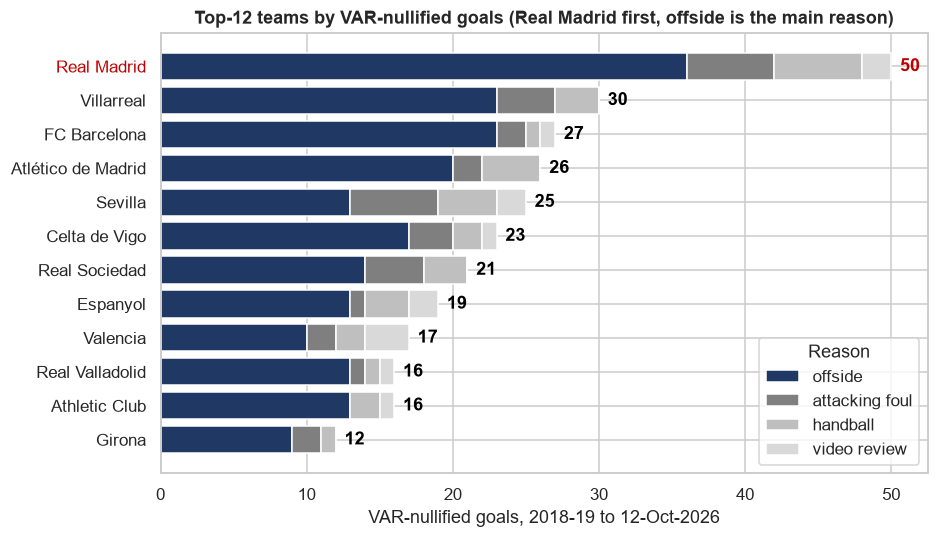

In [3]:
tbl = pd.crosstab(vd.team, vd.reason_fs).reindex(columns=["offside", "Foul", "handball", "video review"], fill_value=0)
tbl["total"] = tbl.sum(axis=1)
tbl = tbl.sort_values("total", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5.2))
colors = {"offside": NAVY, "Foul": "#7F7F7F", "handball": "#BFBFBF", "video review": "#D9D9D9"}
left = np.zeros(len(tbl))
for c in ["offside", "Foul", "handball", "video review"]:
    ax.barh(tbl.index, tbl[c], left=left, color=colors[c], label=c.replace("Foul", "attacking foul"), edgecolor="white")
    left += tbl[c].values
for i, (t, v) in enumerate(tbl.total.items()):
    ax.text(v + 0.6, i, str(v), va="center", fontweight="bold", color=RED if t == RM else "black")
ax.get_yticklabels()[0].set_color(RED)
ax.invert_yaxis(); ax.set_xlabel("VAR-nullified goals, 2018-19 to 12-Oct-2026"); ax.legend(title="Reason", loc="lower right")
ax.set_title("Top-12 teams by VAR-nullified goals (Real Madrid first, offside is the main reason)")
save(fig, "01_team_ranking")

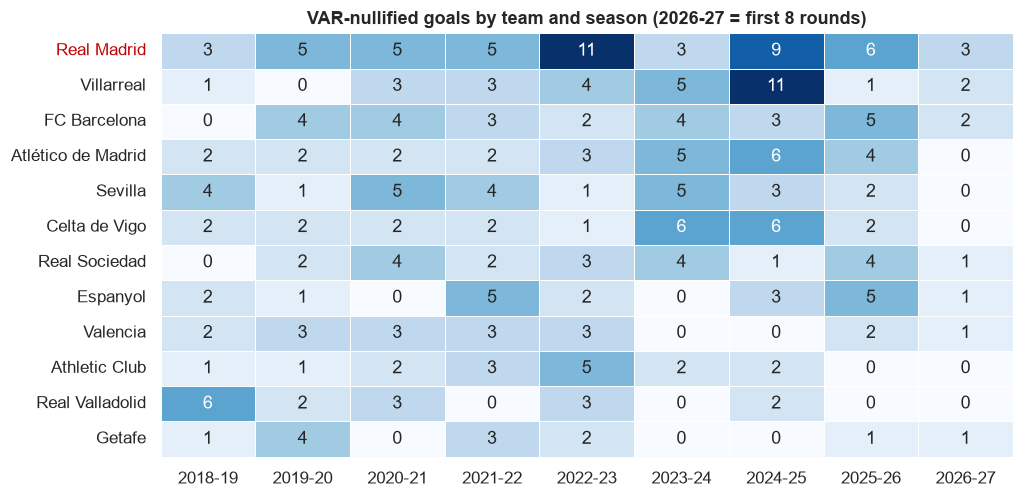

In [4]:
top = vd.team.value_counts().head(12).index
heat = pd.crosstab(vd.team, vd.season).reindex(top)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=.5, ax=ax)
ax.set_title("VAR-nullified goals by team and season (2026-27 = first 8 rounds)"); ax.set_xlabel(""); ax.set_ylabel("")
ax.get_yticklabels()[0].set_color(RED)
save(fig, "02_team_season_heatmap")

## 2. Q1 - How concentrated are the nullified goals by player? (75% rule)
Goals are attributed to the **player whose goal was ruled out** (the scorer). The cumulative share shows how many players account for 75% of the 50 incidents.

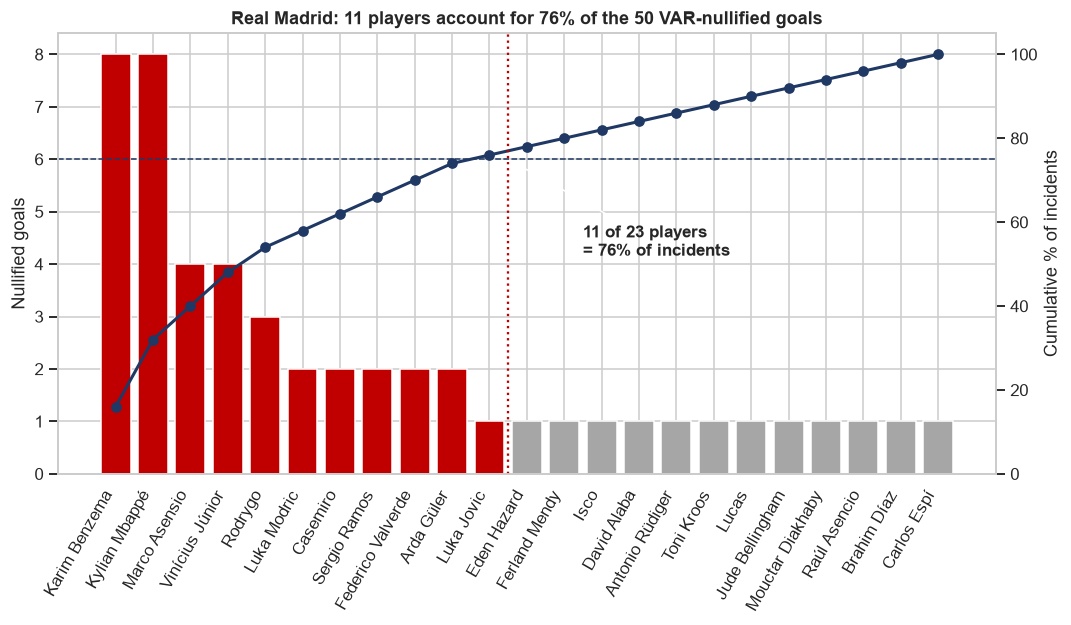

,goals,% of total,cumulative %
player_full,,,
Karim Benzema,8,16.0,16.0
Kylian Mbappé,8,16.0,32.0
Marco Asensio,4,8.0,40.0
Vinícius Júnior,4,8.0,48.0
Rodrygo,3,6.0,54.0
Luka Modric,2,4.0,58.0
Casemiro,2,4.0,62.0
Sergio Ramos,2,4.0,66.0
Federico Valverde,2,4.0,70.0


In [5]:
pc = rm.player_full.value_counts()
cum = pc.cumsum() / pc.sum()
k75 = int((cum < 0.75).sum() + 1)
share75 = cum.iloc[k75 - 1]

fig, ax = plt.subplots(figsize=(11, 5.2))
cols = [RED if i < k75 else GREY for i in range(len(pc))]
ax.bar(range(len(pc)), pc.values, color=cols)
ax.set_xticks(range(len(pc))); ax.set_xticklabels(pc.index, rotation=60, ha="right")
ax.set_ylabel("Nullified goals")
ax2 = ax.twinx()
ax2.plot(range(len(pc)), cum.values * 100, color=NAVY, marker="o", lw=2)
ax2.axhline(75, color=NAVY, ls="--", lw=1); ax2.set_ylim(0, 105); ax2.set_ylabel("Cumulative % of incidents"); ax2.grid(False)
ax2.axvline(k75 - 0.5, color=RED, ls=":", lw=1.5)
ax2.annotate(f"{k75} of {len(pc)} players\n= {share75:.0%} of incidents", xy=(k75 - 0.5, 75), xytext=(k75 + 1.5, 52),
             arrowprops=dict(arrowstyle="->"), fontsize=11, fontweight="bold")
ax.set_title(f"Real Madrid: {k75} players account for {share75:.0%} of the {len(rm)} VAR-nullified goals")
save(fig, "03_player_pareto")
display(pd.DataFrame({"goals": pc, "% of total": (pc / pc.sum() * 100).round(1), "cumulative %": (cum * 100).round(1)}).head(k75 + 3))

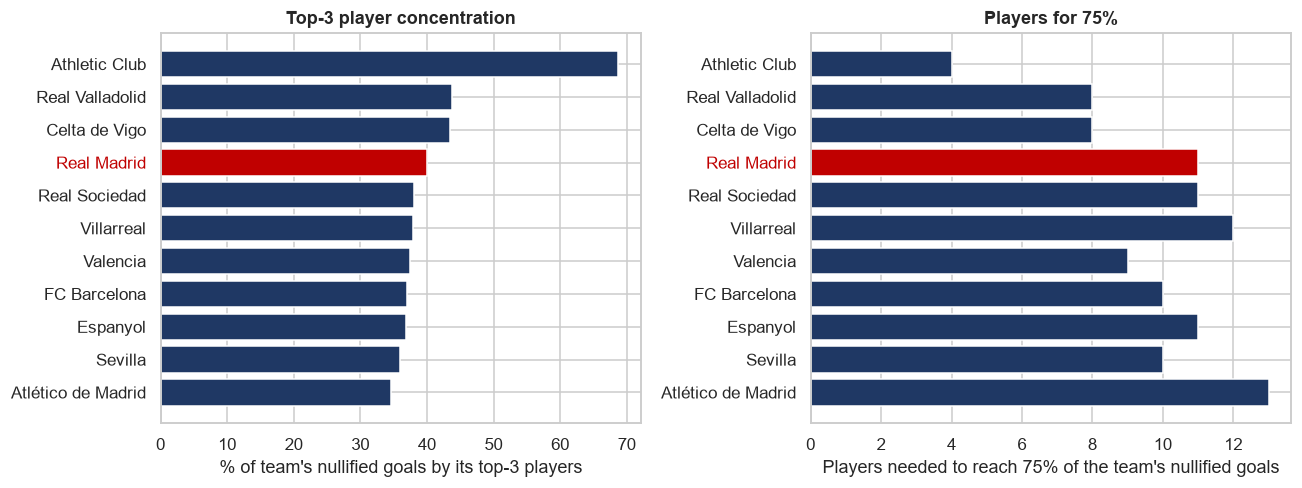

,team,nullified,distinct_players,players_for_75,top1_share,top3_share
0,Athletic Club,16,8,4,0.38,0.69
1,Real Valladolid,16,12,8,0.19,0.44
2,Celta de Vigo,23,13,8,0.17,0.43
3,Real Madrid,50,23,11,0.16,0.40
4,Real Sociedad,21,16,11,0.14,0.38
5,Villarreal,30,19,12,0.14,0.38
6,Valencia,17,13,9,0.12,0.38
7,FC Barcelona,27,16,10,0.15,0.37
8,Espanyol,19,15,11,0.16,0.37
9,Sevilla,25,16,10,0.12,0.36


In [6]:
# Is Real Madrid unusually concentrated compared with the other teams? (teams with >= 15 nullified goals)
rows = []
for t, g in vd.groupby("team"):
    if len(g) < 15:
        continue
    c = g.player_full.value_counts()
    sh = c.cumsum() / c.sum()
    rows.append(dict(team=t, nullified=len(g), distinct_players=len(c), players_for_75=int((sh < 0.75).sum() + 1),
                     top1_share=c.iloc[0] / c.sum(), top3_share=c.iloc[:3].sum() / c.sum()))
conc = pd.DataFrame(rows).sort_values("top3_share", ascending=False).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cc = [RED if t == RM else NAVY for t in conc.team]
axes[0].barh(conc.team, conc.top3_share * 100, color=cc); axes[0].invert_yaxis()
axes[0].set_xlabel("% of team's nullified goals by its top-3 players"); axes[0].set_title("Top-3 player concentration")
axes[1].barh(conc.team, conc.players_for_75, color=cc); axes[1].invert_yaxis()
axes[1].set_xlabel("Players needed to reach 75% of the team's nullified goals"); axes[1].set_title("Players for 75%")
for a in axes:
    a.get_yticklabels()[list(conc.team).index(RM)].set_color(RED)
fig.tight_layout(); save(fig, "04_concentration_vs_teams")
conc.round(2)

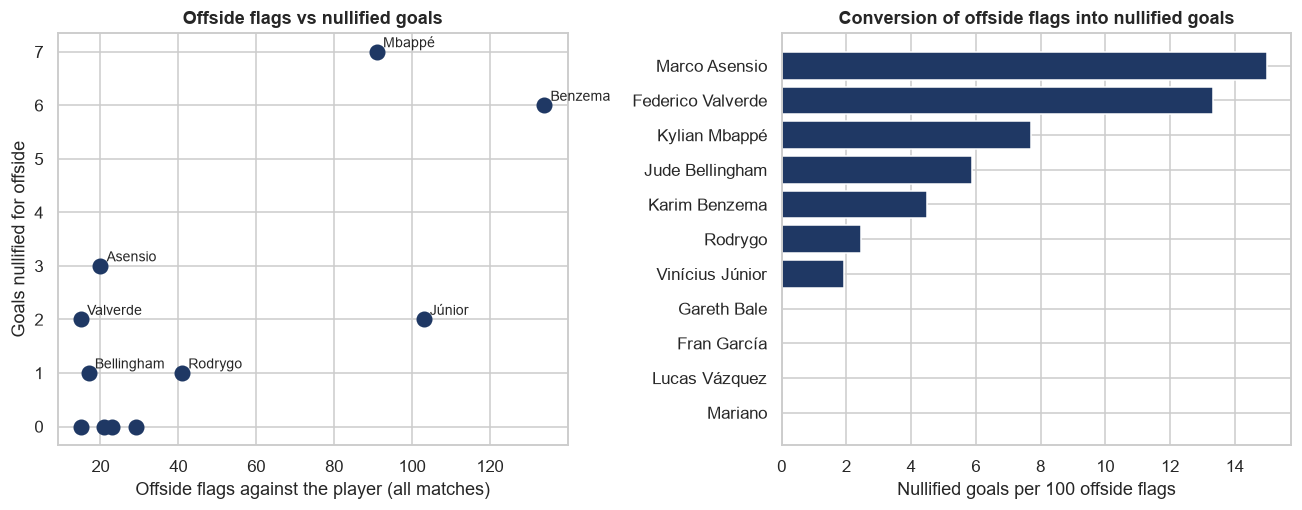

,player,offside_flags,nullified_offside_goals,nullified_per_100_flags
0,Kylian Mbappé,91,7,7.7
1,Karim Benzema,134,6,4.5
2,Marco Asensio,20,3,15.0
3,Vinícius Júnior,103,2,1.9
4,Federico Valverde,15,2,13.3
5,Rodrygo,41,1,2.4
6,Jude Bellingham,17,1,5.9
7,Gareth Bale,21,0,0.0
8,Fran García,15,0,0.0
9,Lucas Vázquez,23,0,0.0


In [7]:
# Per-player view: how many of each player's offside flags ended up as a nullified goal? (ESPN offside events, Real Madrid matches)
# Parsed from the ESPN cache when it is present, otherwise read from the small CSV saved on a previous run.
FLAGS_CSV = P / "eda_rm_offside_flags.csv"
cache_dir = ROOT / "data/raw/espn_cache"
if cache_dir.exists() and any(cache_dir.glob("summary_*.json")):
    es = pd.read_csv(ROOT / "data/raw/espn_matches.csv", dtype={"event_id": str})
    es = es[(es.status == "Full Time") & ((es.home == RM) | (es.away == RM))]
    flags, flag_names = [], {}
    for r in es.itertuples():
        j = json.load(open(cache_dir / f"summary_{r.event_id}.json", encoding="utf8"))
        for c in j.get("commentary") or []:
            t = c.get("text") or ""
            if ((c.get("play") or {}).get("type") or {}).get("text") == "Offside" and t.startswith("Offside, Real Madrid"):
                s = t.split(". ", 1)[1] if ". " in t else t
                s = s.split(" but ")[-1].replace(" is caught offside.", "").strip()
                flag_names.setdefault(key(s), s)
                flags.append(key(s))
    off = pd.Series(flags).value_counts()
    pd.DataFrame({"key": off.index, "offside_flags": off.values, "name": [flag_names[k] for k in off.index]}).to_csv(FLAGS_CSV, index=False, encoding="utf-8-sig")
else:
    _f = pd.read_csv(FLAGS_CSV)
    off = pd.Series(_f.offside_flags.values, index=_f.key)
    flag_names = dict(zip(_f.key, _f.name))
nul = rm[rm.reason_fs == "offside"].groupby(rm.player_full.map(key)).size()
names = {**flag_names, **rm.groupby(rm.player_full.map(key)).player_full.first().to_dict()}
pl = pd.DataFrame({"offside_flags": off, "nullified_offside_goals": nul}).fillna(0).astype(int)
pl["player"] = pl.index.map(lambda k: names.get(k, k.title()))
pl = pl[(pl.offside_flags >= 15) | (pl.nullified_offside_goals >= 3)].copy()
pl["nullified_per_100_flags"] = 100 * pl.nullified_offside_goals / pl.offside_flags
pl = pl.sort_values("nullified_offside_goals", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(pl.offside_flags, pl.nullified_offside_goals, s=90, color=NAVY)
for r in pl.itertuples():
    if r.nullified_offside_goals > 0 or r.offside_flags >= 40:
        axes[0].annotate(r.player.split()[-1], (r.offside_flags, r.nullified_offside_goals), xytext=(4, 3), textcoords="offset points", fontsize=9)
axes[0].set_xlabel("Offside flags against the player (all matches)"); axes[0].set_ylabel("Goals nullified for offside")
axes[0].set_title("Offside flags vs nullified goals")
p2 = pl.sort_values("nullified_per_100_flags", ascending=False)
axes[1].barh(p2.player, p2.nullified_per_100_flags, color=NAVY); axes[1].invert_yaxis()
axes[1].set_xlabel("Nullified goals per 100 offside flags"); axes[1].set_title("Conversion of offside flags into nullified goals")
fig.tight_layout(); save(fig, "05_player_offside_flags")
pl[["player", "offside_flags", "nullified_offside_goals", "nullified_per_100_flags"]].round(1).reset_index(drop=True)

## 3. Q2 - How many matches were directly affected (draw or loss)?
Two readings are shown:
1. **Draw/loss matches** (your definition): matches that contain a nullified goal and ended in a draw or defeat.
2. **Result would have changed**: if *all* nullified goals of the match had counted (loss to draw/win, draw to win). Wins can't lose points, and heavy defeats can stay defeats.

In [8]:
g = rm.groupby("fs_id").agg(date=("kickoff", "first"), season=("season", "first"), rival=("opponent", "first"), venue=("venue", "first"),
                            nullified=("fs_id", "size"), gf=("team_gf", "first"), ga=("team_ga", "first"),
                            reasons=("reason_fs", lambda s: ", ".join(sorted(set(s))))).reset_index()
g["outcome"] = np.where(g.gf > g.ga, "WIN", np.where(g.gf == g.ga, "DRAW", "LOSS"))
g["pts_actual"] = pts_fn(g.gf, g.ga)
g["pts_if_counted"] = pts_fn(g.gf + g.nullified, g.ga)
g["points_lost"] = g.pts_if_counted - g.pts_actual
g["result_change"] = np.select([(g.outcome == "LOSS") & (g.pts_if_counted == 1), (g.outcome == "LOSS") & (g.pts_if_counted == 3),
                                (g.outcome == "DRAW") & (g.pts_if_counted == 3)], ["Loss -> Draw", "Loss -> Win", "Draw -> Win"], "No change")
g = g.sort_values("date").reset_index(drop=True)

n_goals, n_matches = len(rm), len(g)
dl = g[g.outcome != "WIN"]
chg = g[g.result_change != "No change"]
summary = pd.DataFrame({
    "count": [n_goals, n_matches, len(dl), len(chg), int(g.points_lost.sum())],
    "% of Real Madrid league matches": [np.nan, 100 * n_matches / len(rm_matches), 100 * len(dl) / len(rm_matches), 100 * len(chg) / len(rm_matches), np.nan],
    "% of matches with a nullified goal": [np.nan, 100.0, 100 * len(dl) / n_matches, 100 * len(chg) / n_matches, np.nan]},
    index=["Nullified goals", "Matches with a nullified goal", "...ended in a draw or loss (direct-effect candidates)",
           "...where the result would have changed", "Points that would have been gained"]).round(1)
display(summary)
display(g.groupby("outcome").agg(matches=("fs_id", "size"), nullified_goals=("nullified", "sum")).reindex(["WIN", "DRAW", "LOSS"]))
display(pd.crosstab(g.outcome, g.result_change))

,count,% of Real Madrid league matches,% of matches with a nullified goal
Nullified goals,50,NaN,NaN
Matches with a nullified goal,44,14.1,100.0
...ended in a draw or loss (direct-effect candidates),15,4.8,34.1
...where the result would have changed,13,4.2,29.5
Points that would have been gained,21,NaN,NaN


,matches,nullified_goals
outcome,,
WIN,29,35
DRAW,8,8
LOSS,7,7


result_change,Draw -> Win,Loss -> Draw,No change
outcome,,,
DRAW,8,0,0
LOSS,0,5,2
WIN,0,0,29


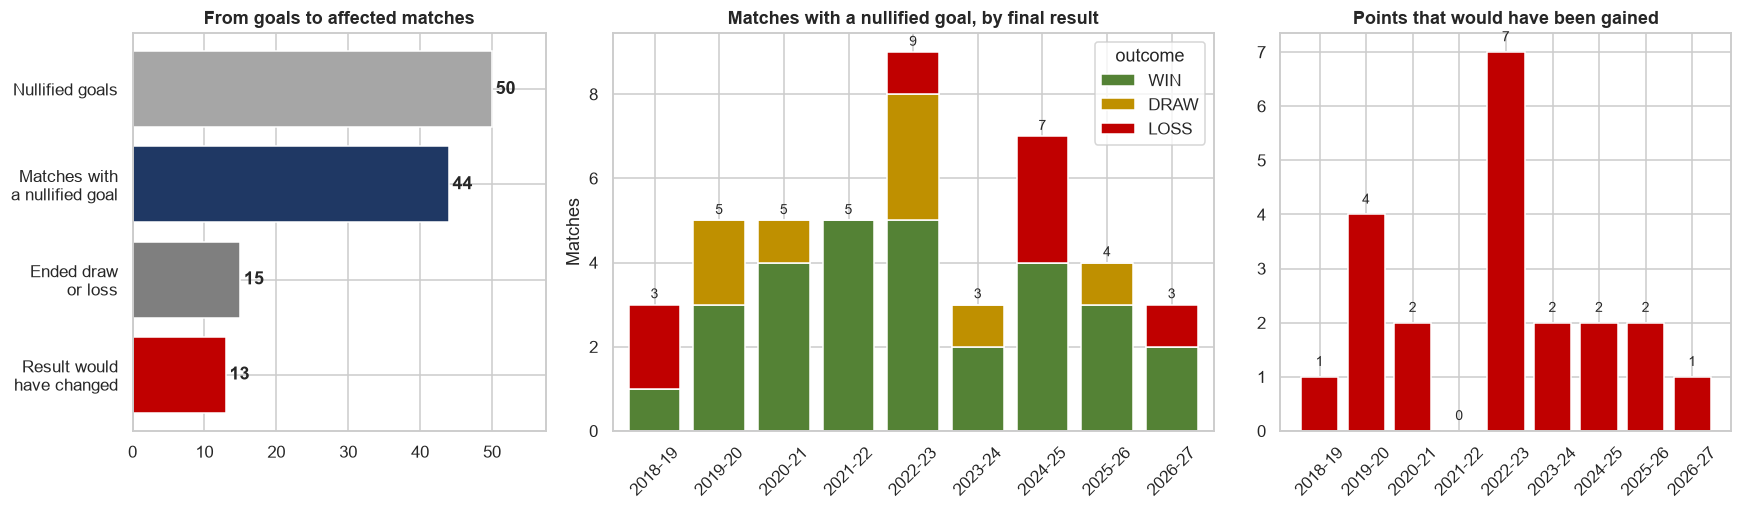

,date,season,rival,venue,gf,ga,nullified,reasons,result_change,points_lost
1,2018-10-20,2018-19,Levante,Home,1,2,1,offside,Loss -> Draw,1
4,2019-11-02,2019-20,Real Betis,Home,0,0,1,offside,Draw -> Win,2
6,2020-02-16,2019-20,Celta de Vigo,Home,2,2,1,offside,Draw -> Win,2
11,2021-05-09,2020-21,Sevilla,Home,2,2,1,offside,Draw -> Win,2
18,2022-10-02,2022-23,Osasuna,Home,1,1,1,offside,Draw -> Win,2
21,2022-10-30,2022-23,Girona,Home,1,1,1,video review,Draw -> Win,2
24,2023-03-05,2022-23,Real Betis,Away,0,0,1,handball,Draw -> Win,2
25,2023-03-19,2022-23,FC Barcelona,Away,1,2,1,offside,Loss -> Draw,1
28,2023-10-21,2023-24,Sevilla,Away,1,1,1,offside,Draw -> Win,2
31,2024-12-04,2024-25,Athletic Club,Away,1,2,1,offside,Loss -> Draw,1


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1.6, 1.2]})
vals = [n_goals, n_matches, len(dl), len(chg)]
labs = ["Nullified goals", "Matches with\na nullified goal", "Ended draw\nor loss", "Result would\nhave changed"]
axes[0].barh(labs, vals, color=[GREY, NAVY, "#7F7F7F", RED]); axes[0].invert_yaxis()
for i, v in enumerate(vals):
    axes[0].text(v + 0.5, i, str(v), va="center", fontweight="bold")
axes[0].set_title("From goals to affected matches"); axes[0].set_xlim(0, max(vals) * 1.15)

ct = pd.crosstab(g.season, g.outcome).reindex(columns=["WIN", "DRAW", "LOSS"], fill_value=0).reindex(seasons, fill_value=0)
ct.plot(kind="bar", stacked=True, ax=axes[1], color=["#548235", "#BF9000", RED], width=.8)
axes[1].set_title("Matches with a nullified goal, by final result"); axes[1].set_xlabel(""); axes[1].set_ylabel("Matches")
axes[1].tick_params(axis="x", rotation=45)
for i, (s, row) in enumerate(ct.iterrows()):
    axes[1].text(i, row.sum() + .15, str(int(row.sum())), ha="center", fontsize=9)

pl_ = g.groupby("season").points_lost.sum().reindex(seasons, fill_value=0)
axes[2].bar(pl_.index, pl_.values, color=RED); axes[2].set_title("Points that would have been gained")
axes[2].tick_params(axis="x", rotation=45)
for i, v in enumerate(pl_.values):
    axes[2].text(i, v + .2, int(v), ha="center", fontsize=9)
fig.tight_layout(); save(fig, "06_games_affected")
g[g.result_change != "No change"][["date", "season", "rival", "venue", "gf", "ga", "nullified", "reasons", "result_change", "points_lost"]].assign(date=lambda x: x.date.dt.date)

## 4. Q3 - Nullified goals when Real Madrid was champion vs not champion
Champion = finished 1st in the rebuilt final table (2019-20, 2021-22, 2023-24). 2026-27 is in progress and shown separately.

In [10]:
champ = ft[ft.final_pos == 1].set_index("season").team
rmpos = ft[ft.team == RM].set_index("season").final_pos
rmpts = ft[ft.team == RM].set_index("season").pts
ss = pd.DataFrame({"season": seasons})
ss["status"] = ["In progress" if s == "2026-27" else "Champion" if champ.get(s) == RM else "Not champion" for s in seasons]
ss["rm_final_pos"] = ss.season.map(rmpos); ss["rm_points"] = ss.season.map(rmpts); ss["league_champion"] = ss.season.map(champ)
ss["matches"] = ss.season.map(rm_matches.groupby("season").size())
ss["nullified"] = ss.season.map(rm.groupby("season").size()).fillna(0).astype(int)
ss["per_match"] = ss.nullified / ss.matches
ss["per_38"] = ss.per_match * 38
ss["points_lost_if_counted"] = ss.season.map(g.groupby("season").points_lost.sum()).fillna(0).astype(int)
ss["matches_with_nullified"] = ss.season.map(g.groupby("season").size()).fillna(0).astype(int)
display(ss.round(3))

grp = ss.groupby("status").agg(seasons=("season", "size"), matches=("matches", "sum"), nullified=("nullified", "sum"),
                               points_lost=("points_lost_if_counted", "sum"), matches_with_nullified=("matches_with_nullified", "sum"))
grp["% of all RM nullified goals"] = 100 * grp.nullified / grp.nullified.sum()
grp["% of RM matches"] = 100 * grp.matches / grp.matches.sum()
grp["per match"] = grp.nullified / grp.matches
grp["per 38 matches"] = grp["per match"] * 38
lo = stats.chi2.ppf(.025, 2 * grp.nullified) / 2 / grp.matches * 38
hi = stats.chi2.ppf(.975, 2 * (grp.nullified + 1)) / 2 / grp.matches * 38
grp["95% CI low (per 38)"], grp["95% CI high (per 38)"] = lo, hi
display(grp.round(3))

ch, nc = grp.loc["Champion"], grp.loc["Not champion"]
tot = ch.nullified + nc.nullified
bt = stats.binomtest(int(ch.nullified), int(tot), ch.matches / (ch.matches + nc.matches))
rr = (ch.nullified / ch.matches) / (nc.nullified / nc.matches)
md(f"**Champion seasons: {int(ch.nullified)} nullified goals ({ch['per 38 matches']:.1f} per 38 matches) vs not-champion seasons: {int(nc.nullified)} ({nc['per 38 matches']:.1f} per 38)** - "
   f"rate ratio {rr:.2f} (two-sided exact p = {bt.pvalue:.3f}). The rate is lower in title seasons, but the difference is {'' if bt.pvalue < 0.05 else 'not '}statistically significant.")

,season,status,rm_final_pos,rm_points,league_champion,matches,nullified,per_match,per_38,points_lost_if_counted,matches_with_nullified
0,2018-19,Not champion,3,68,FC Barcelona,38,3,0.079,3.00,1,3
1,2019-20,Champion,1,87,Real Madrid,38,5,0.132,5.00,4,5
2,2020-21,Not champion,2,84,Atlético de Madrid,38,5,0.132,5.00,2,5
3,2021-22,Champion,1,86,Real Madrid,38,5,0.132,5.00,0,5
4,2022-23,Not champion,2,78,FC Barcelona,38,11,0.289,11.00,7,9
5,2023-24,Champion,1,95,Real Madrid,38,3,0.079,3.00,2,3
6,2024-25,Not champion,2,84,FC Barcelona,38,9,0.237,9.00,2,7
7,2025-26,Not champion,2,86,FC Barcelona,38,6,0.158,6.00,2,4
8,2026-27,In progress,4,18,FC Barcelona,8,3,0.375,14.25,1,3


,seasons,matches,nullified,points_lost,matches_with_nullified,% of all RM nullified goals,% of RM matches,per match,per 38 matches,95% CI low (per 38),95% CI high (per 38)
status,,,,,,,,,,,
Champion,3,114,13,6,13,26.0,36.538,0.114,4.333,2.307,7.410
In progress,1,8,3,1,3,6.0,2.564,0.375,14.250,2.939,41.645
Not champion,5,190,34,14,28,68.0,60.897,0.179,6.800,4.709,9.502


**Champion seasons: 13 nullified goals (4.3 per 38 matches) vs not-champion seasons: 34 (6.8 per 38)** - rate ratio 0.64 (two-sided exact p = 0.178). The rate is lower in title seasons, but the difference is not statistically significant.

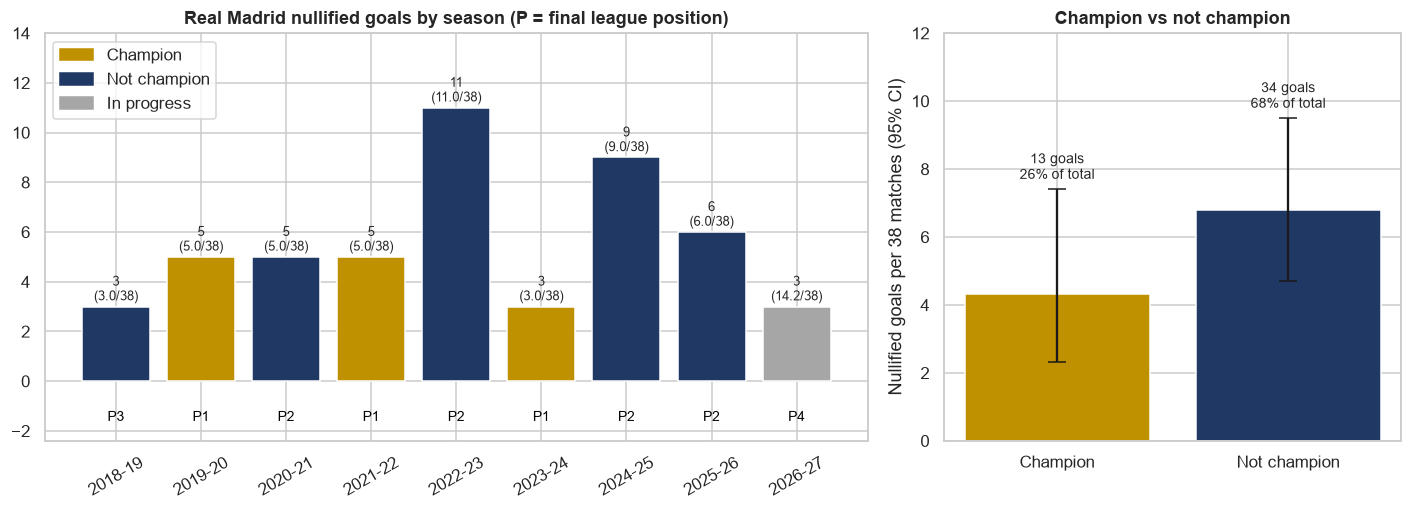

reason_fs,Attacking foul,Handball,Offside,Video review
season,,,,
Champion,3,2,8,0
In progress,1,0,2,0
Not champion,2,4,26,2


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.8, 1]})
colmap = {"Champion": GOLD, "Not champion": NAVY, "In progress": GREY}
axes[0].bar(ss.season, ss.nullified, color=[colmap[s] for s in ss.status])
for i, r in ss.iterrows():
    axes[0].text(i, r.nullified + .25, f"{r.nullified}\n({r.per_38:.1f}/38)", ha="center", fontsize=8.5)
    axes[0].text(i, -1.6, f"P{int(r.rm_final_pos)}", ha="center", fontsize=9, color="black")
axes[0].set_ylim(-2.4, 14); axes[0].set_title("Real Madrid nullified goals by season (P = final league position)")
axes[0].tick_params(axis="x", rotation=30)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in colmap.items()], loc="upper left")
gg = grp.loc[["Champion", "Not champion"]]
axes[1].bar(gg.index, gg["per 38 matches"], color=[GOLD, NAVY],
            yerr=[gg["per 38 matches"] - gg["95% CI low (per 38)"], gg["95% CI high (per 38)"] - gg["per 38 matches"]], capsize=6)
for i, (k, r) in enumerate(gg.iterrows()):
    axes[1].text(i, r["95% CI high (per 38)"] + .3, f"{int(r.nullified)} goals\n{r['% of all RM nullified goals']:.0f}% of total", ha="center", fontsize=9)
axes[1].set_ylabel("Nullified goals per 38 matches (95% CI)"); axes[1].set_title("Champion vs not champion"); axes[1].set_ylim(0, 12)
fig.tight_layout(); save(fig, "07_champion_vs_not")
display(pd.crosstab(rm.season.map(ss.set_index("season").status), rm.reason_fs.map({"offside": "Offside", "Foul": "Attacking foul", "handball": "Handball", "video review": "Video review"})))

## 5. Q4 - Title scenario analysis: would the nullified goals have changed any La Liga title?
**Method.** Every league season is rebuilt from all 380 match results and re-sorted with the La Liga tie-break order (points, head-to-head points, head-to-head goal difference, overall goal difference, goals scored).
Then goals are added back to the affected matches and the **whole season table is recomputed** (so the opponents also lose the points Real Madrid gains, and positions are re-ranked):

| Scenario | Goals added back |
|---|---|
| **A. Real Madrid only (VAR)** | all 50 Real Madrid VAR-nullified goals (upper bound: assumes every nullification was wrong) |
| **B. Everyone (VAR)** | all VAR-nullified goals of all teams (a world with no VAR goal-nullifications) |
| **C. Real Madrid only (VAR + on-field)** | Real Madrid VAR goals + goals ruled out on the pitch (sensitivity) |

Then a break-even analysis (how many wrong calls would be needed) and a Monte-Carlo with realistic VAR error rates.

In [12]:
def league_table(ms):
    h = ms.rename(columns={"home": "team", "away": "opp", "hg": "gf", "ag": "ga"})[["team", "opp", "gf", "ga"]]
    a = ms.rename(columns={"away": "team", "home": "opp", "ag": "gf", "hg": "ga"})[["team", "opp", "gf", "ga"]]
    long = pd.concat([h, a], ignore_index=True)
    long["pts"] = pts_fn(long.gf, long.ga)
    t = long.groupby("team").agg(P=("pts", "size"), pts=("pts", "sum"), gf=("gf", "sum"), ga=("ga", "sum")).reset_index()
    t["gd"] = t.gf - t.ga
    out = []
    for v in sorted(t.pts.unique(), reverse=True):
        grp_ = t[t.pts == v]
        if len(grp_) > 1:                                          # head-to-head mini-league among tied teams
            sub = long[long.team.isin(grp_.team) & long.opp.isin(grp_.team)]
            h2h = sub.groupby("team").agg(h_pts=("pts", "sum"), h_gf=("gf", "sum"), h_ga=("ga", "sum"))
            h2h["h_gd"] = h2h.h_gf - h2h.h_ga
            grp_ = grp_.merge(h2h[["h_pts", "h_gd"]], left_on="team", right_index=True, how="left").fillna(0)
            grp_ = grp_.sort_values(["h_pts", "h_gd", "gd", "gf", "team"], ascending=[False, False, False, False, True])
        out.append(grp_)
    res = pd.concat(out, ignore_index=True)[["team", "P", "pts", "gf", "ga", "gd"]]
    res.insert(0, "pos", range(1, len(res) + 1))
    return res


def season_matches(s):
    x = mt[mt.season == s][["fs_id", "home", "away", "home_goals", "away_goals"]].rename(columns={"home_goals": "hg", "away_goals": "ag"})
    x[["hg", "ag"]] = x[["hg", "ag"]].astype(int)
    return x.reset_index(drop=True)


def adjusted(ms, adds):
    ms = ms.copy()
    for (fid, team), n in adds.items():
        i = ms.index[ms.fs_id == fid]
        if len(i):
            ms.loc[i[0], "hg" if ms.loc[i[0], "home"] == team else "ag"] += n
    return ms


A_adds = rm.groupby(["fs_id", "team"]).size().to_dict()
B_adds = vd.groupby(["fs_id", "team"]).size().to_dict()
C_adds = dict(A_adds)
for (fid, team), n in onf[onf.team == RM].groupby(["fs_id", "team"]).size().items():
    C_adds[(fid, team)] = C_adds.get((fid, team), 0) + n
scen_adds = {"Actual": {}, "A. Real Madrid only (VAR)": A_adds, "B. Everyone (VAR)": B_adds, "C. Real Madrid only (VAR + on-field)": C_adds}

tables = {(s, sc): league_table(adjusted(season_matches(s), adds)) for s in seasons for sc, adds in scen_adds.items()}

# validation of the rebuilt actual tables against the earlier table (points/GD/GF tie-break) and known champions
chk = []
for s in seasons:
    a = tables[(s, "Actual")]
    f_ = ft[ft.season == s].sort_values("final_pos")
    chk.append(dict(season=s, champion=a.team.iloc[0], champion_pts=int(a.pts.iloc[0]), rm_pos=int(a[a.team == RM].pos.iloc[0]), rm_pts=int(a[a.team == RM].pts.iloc[0]),
                    same_top4_as_earlier_table=list(a.team.head(4)) == list(f_.team.head(4)),
                    max_pos_diff_vs_earlier=int((a.set_index("team").pos - f_.set_index("team").final_pos).abs().max())))
display(pd.DataFrame(chk))

,season,champion,champion_pts,rm_pos,rm_pts,same_top4_as_earlier_table,max_pos_diff_vs_earlier
0,2018-19,FC Barcelona,87,3,68,True,1
1,2019-20,Real Madrid,87,1,87,True,0
2,2020-21,Atlético de Madrid,86,2,84,True,1
3,2021-22,Real Madrid,86,1,86,True,1
4,2022-23,FC Barcelona,88,2,78,True,2
5,2023-24,Real Madrid,95,1,95,True,1
6,2024-25,FC Barcelona,88,2,84,True,1
7,2025-26,FC Barcelona,94,2,86,True,2
8,2026-27,FC Barcelona,24,4,18,True,5


In [13]:
rows = []
for s in seasons:
    for sc in scen_adds:
        t = tables[(s, sc)]
        r_ = t[t.team == RM].iloc[0]
        others = t[t.team != RM]
        best = others.iloc[0]
        rows.append(dict(season=s, scenario=sc, rm_pos=int(r_.pos), rm_pts=int(r_.pts), rm_gd=int(r_.gd), champion=t.team.iloc[0], champion_pts=int(t.pts.iloc[0]),
                         best_rival=best.team, best_rival_pts=int(best.pts), lead_over_best_rival=int(r_.pts - best.pts)))
sc_df = pd.DataFrame(rows)
act = sc_df[sc_df.scenario == "Actual"].set_index("season")
sc_df["rm_pts_change"] = sc_df.rm_pts - sc_df.season.map(act.rm_pts)
sc_df["title_changed"] = (sc_df.champion != sc_df.season.map(act.champion))
sc_df["rm_champion"] = sc_df.champion == RM
display(sc_df.pivot(index="season", columns="scenario", values="rm_pos")[list(scen_adds)].rename_axis("Real Madrid league position"))
display(sc_df.pivot(index="season", columns="scenario", values="rm_pts")[list(scen_adds)].rename_axis("Real Madrid points"))
display(sc_df.pivot(index="season", columns="scenario", values="champion")[list(scen_adds)].rename_axis("Champion"))

scenario,Actual,A. Real Madrid only (VAR),B. Everyone (VAR),C. Real Madrid only (VAR + on-field)
Real Madrid league position,,,,
2018-19,3,3,3,3
2019-20,1,1,1,1
2020-21,2,1,1,1
2021-22,1,1,1,1
2022-23,2,2,1,1
2023-24,1,1,2,1
2024-25,2,2,2,1
2025-26,2,2,2,2
2026-27,4,3,3,3


scenario,Actual,A. Real Madrid only (VAR),B. Everyone (VAR),C. Real Madrid only (VAR + on-field)
Real Madrid points,,,,
2018-19,68,69,69,73
2019-20,87,91,91,91
2020-21,84,86,86,88
2021-22,86,86,84,87
2022-23,78,85,85,87
2023-24,95,97,87,99
2024-25,84,86,86,90
2025-26,86,88,88,88
2026-27,18,19,19,19


scenario,Actual,A. Real Madrid only (VAR),B. Everyone (VAR),C. Real Madrid only (VAR + on-field)
Champion,,,,
2018-19,FC Barcelona,FC Barcelona,FC Barcelona,FC Barcelona
2019-20,Real Madrid,Real Madrid,Real Madrid,Real Madrid
2020-21,Atlético de Madrid,Real Madrid,Real Madrid,Real Madrid
2021-22,Real Madrid,Real Madrid,Real Madrid,Real Madrid
2022-23,FC Barcelona,FC Barcelona,Real Madrid,Real Madrid
2023-24,Real Madrid,Real Madrid,FC Barcelona,Real Madrid
2024-25,FC Barcelona,FC Barcelona,FC Barcelona,Real Madrid
2025-26,FC Barcelona,FC Barcelona,FC Barcelona,FC Barcelona
2026-27,FC Barcelona,FC Barcelona,FC Barcelona,FC Barcelona


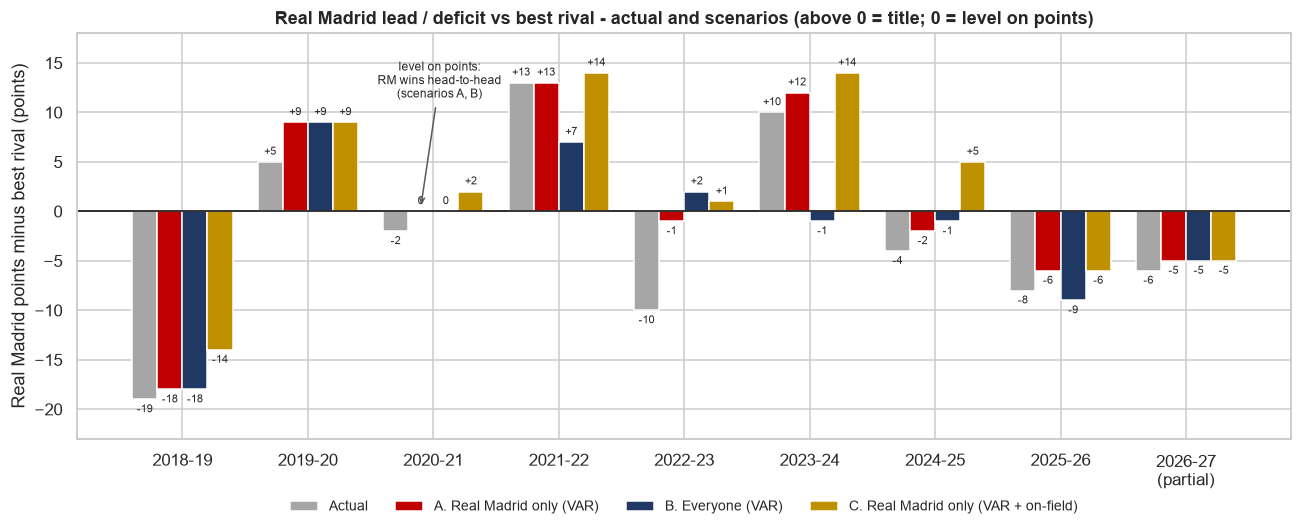

In [14]:
# Figure: lead/deficit vs the best rival, actual vs scenarios (positive = Real Madrid champion)
fig, ax = plt.subplots(figsize=(12, 5))
w = .2
cols = {"Actual": GREY, "A. Real Madrid only (VAR)": RED, "B. Everyone (VAR)": NAVY, "C. Real Madrid only (VAR + on-field)": GOLD}
for i, (sc, c) in enumerate(cols.items()):
    x = sc_df[sc_df.scenario == sc].set_index("season").reindex(seasons)
    xs_ = np.arange(len(seasons)) + (i - 1.5) * w
    ax.bar(xs_, x.lead_over_best_rival, width=w, color=c, label=sc)
    for xx, v in zip(xs_, x.lead_over_best_rival):
        ax.text(xx, v + (0.5 if v >= 0 else -0.5), f"{int(v):+d}" if v else "0", ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(len(seasons))); ax.set_xticklabels([s + ("\n(partial)" if s == "2026-27" else "") for s in seasons])
ax.set_ylabel("Real Madrid points minus best rival (points)"); ax.set_ylim(-23, 18)
ax.set_title("Real Madrid lead / deficit vs best rival - actual and scenarios (above 0 = title; 0 = level on points)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9, frameon=False)
i20 = seasons.index("2020-21")
ax.annotate("level on points:\nRM wins head-to-head\n(scenarios A, B)", xy=(i20 - 0.1, 0.4), xytext=(i20 + 0.05, 11.5), fontsize=8, ha="center", arrowprops=dict(arrowstyle="->", color="#595959"))
fig.tight_layout(); save(fig, "08_title_scenarios_gap")

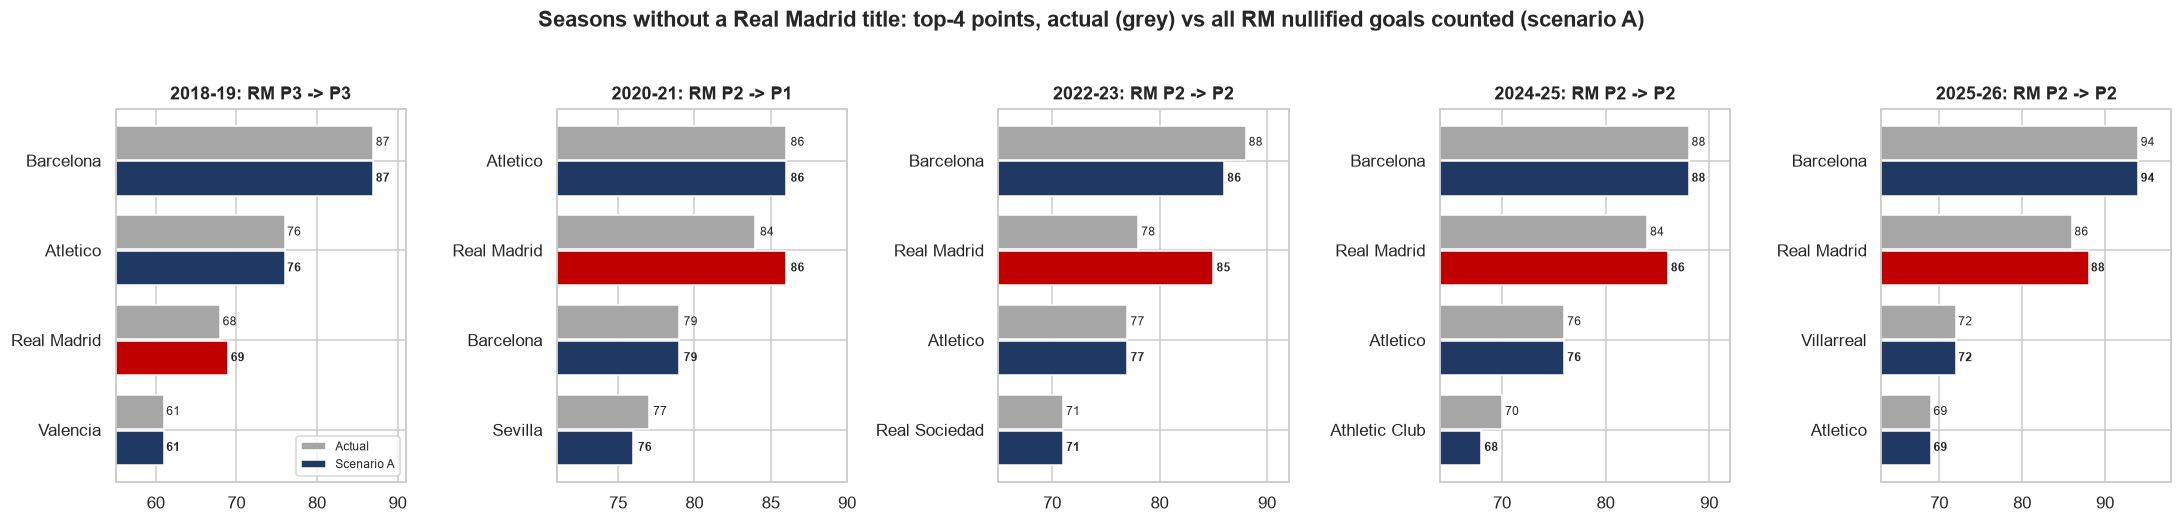

In [15]:
# Where RM did not win the title (full seasons): top-5 table before/after scenario A, side by side
no_title = [s for s in seasons if s != "2026-27" and act.loc[s, "champion"] != RM]
fig, axes = plt.subplots(1, len(no_title), figsize=(4.0 * len(no_title), 4.6), sharex=False)
for ax, s in zip(np.atleast_1d(axes), no_title):
    a = tables[(s, "Actual")].head(4).set_index("team")
    b = tables[(s, "A. Real Madrid only (VAR)")].set_index("team").loc[a.index]
    y = np.arange(len(a))
    ax.barh(y - .2, a.pts, height=.38, color=GREY, label="Actual")
    ax.barh(y + .2, b.pts, height=.38, color=[RED if t == RM else NAVY for t in a.index], label="Scenario A")
    ax.set_yticks(y); ax.set_yticklabels([t.replace("Atlético de Madrid", "Atletico").replace("FC Barcelona", "Barcelona") for t in a.index]); ax.invert_yaxis()
    lo_, hi_ = a.pts.min() - 6, max(a.pts.max(), b.pts.max()) + 4
    ax.set_xlim(lo_, hi_)
    for yy, (t, r_) in zip(y, a.iterrows()):
        ax.text(r_.pts + .3, yy - .2, int(r_.pts), va="center", fontsize=8)
        ax.text(b.loc[t].pts + .3, yy + .2, int(b.loc[t].pts), va="center", fontsize=8, fontweight="bold")
    pos_b = int(tables[(s, "A. Real Madrid only (VAR)")].set_index("team").loc[RM].pos)
    ax.set_title(f"{s}: RM P{int(tables[(s, 'Actual')].set_index('team').loc[RM].pos)} -> P{pos_b}")
axes_ = np.atleast_1d(axes); axes_[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Seasons without a Real Madrid title: top-4 points, actual (grey) vs all RM nullified goals counted (scenario A)", y=1.03, fontweight="bold")
fig.tight_layout(); save(fig, "09_title_scenarios_top4")

In [16]:
# Full leaderboard (top 5) before / after for the seasons where Real Madrid finished 2nd or 3rd
for s in no_title:
    a = tables[(s, "Actual")].head(5).drop(columns=["P"]).rename(columns=lambda c: f"{c} (actual)" if c != "team" else "team")
    b = tables[(s, "A. Real Madrid only (VAR)")]
    b = b.set_index("team").loc[a.team].reset_index()[["team", "pos", "pts", "gd"]].rename(columns={"pos": "pos (A)", "pts": "pts (A)", "gd": "gd (A)"})
    md(f"**{s}** - actual top 5 vs scenario A (Real Madrid's {int(act.loc[s, 'rm_pts'])} pts -> {int(sc_df[(sc_df.season == s) & (sc_df.scenario.str.startswith('A.'))].rm_pts.iloc[0])} pts)")
    display(a.merge(b, on="team").drop(columns=["gf (actual)", "ga (actual)"]))

**2018-19** - actual top 5 vs scenario A (Real Madrid's 68 pts -> 69 pts)

,pos (actual),team,pts (actual),gd (actual),pos (A),pts (A),gd (A)
0,1,FC Barcelona,87,54,1,87,54
1,2,Atlético de Madrid,76,26,2,76,26
2,3,Real Madrid,68,17,3,69,20
3,4,Valencia,61,16,4,61,16
4,5,Getafe,59,13,5,59,13


**2020-21** - actual top 5 vs scenario A (Real Madrid's 84 pts -> 86 pts)

,pos (actual),team,pts (actual),gd (actual),pos (A),pts (A),gd (A)
0,1,Atlético de Madrid,86,42,2,86,42
1,2,Real Madrid,84,39,1,86,44
2,3,FC Barcelona,79,47,3,79,47
3,4,Sevilla,77,20,4,76,19
4,5,Real Sociedad,62,21,5,62,21


**2022-23** - actual top 5 vs scenario A (Real Madrid's 78 pts -> 85 pts)

,pos (actual),team,pts (actual),gd (actual),pos (A),pts (A),gd (A)
0,1,FC Barcelona,88,50,1,86,49
1,2,Real Madrid,78,39,2,85,50
2,3,Atlético de Madrid,77,37,3,77,37
3,4,Real Sociedad,71,16,4,71,16
4,5,Villarreal,64,19,5,64,19


**2024-25** - actual top 5 vs scenario A (Real Madrid's 84 pts -> 86 pts)

,pos (actual),team,pts (actual),gd (actual),pos (A),pts (A),gd (A)
0,1,FC Barcelona,88,63,1,88,62
1,2,Real Madrid,84,40,2,86,49
2,3,Atlético de Madrid,76,38,3,76,38
3,4,Athletic Club,70,25,5,68,23
4,5,Villarreal,70,20,4,70,20


**2025-26** - actual top 5 vs scenario A (Real Madrid's 86 pts -> 88 pts)

,pos (actual),team,pts (actual),gd (actual),pos (A),pts (A),gd (A)
0,1,FC Barcelona,94,59,1,94,58
1,2,Real Madrid,86,42,2,88,48
2,3,Villarreal,72,26,3,72,26
3,4,Atlético de Madrid,69,18,4,69,18
4,5,Real Betis,60,11,5,60,11


In [17]:
# Break-even: smallest number of nullified goals that would have had to be WRONG for Real Madrid to win the title
def max_closure(s):
    ms = season_matches(s)
    t = tables[(s, "Actual")]
    L = t[t.team != RM].iloc[0].team
    gap = int(t[t.team == L].pts.iloc[0] - t[t.team == RM].pts.iloc[0])
    items = []
    for (fid, team), k in A_adds.items():
        x = ms[ms.fs_id == fid]
        if x.empty:
            continue
        x = x.iloc[0]
        gf, ga = (x.hg, x.ag) if x.home == team else (x.ag, x.hg)
        opp = x.away if x.home == team else x.home
        opts = [0]
        for w in range(1, k + 1):
            gain = int(pts_fn(gf + w, ga) - pts_fn(gf, ga))
            loss_L = int(pts_fn(ga, gf) - pts_fn(ga, gf + w)) if opp == L else 0
            opts.append(gain + loss_L)
        items.append(opts)
    best = {0: 0}
    for opts in items:
        nb = dict(best)
        for m_, v in best.items():
            for w, c in enumerate(opts):
                if w and nb.get(m_ + w, -1) < v + c:
                    nb[m_ + w] = v + c
        best = nb
    ms_ = sorted(best)
    return L, gap, best, ms_

def h2h_tiebreak(s, L):
    # does Real Madrid win the head-to-head tie-break against L (head-to-head points, then head-to-head goal difference)?
    ms = season_matches(s)
    x = ms[((ms.home == RM) & (ms.away == L)) | ((ms.home == L) & (ms.away == RM))]
    rp = lp = gd = 0
    for r in x.itertuples():
        rg, lg = (r.hg, r.ag) if r.home == RM else (r.ag, r.hg)
        rp += int(pts_fn(rg, lg)); lp += int(pts_fn(lg, rg)); gd += rg - lg
    return rp > lp or (rp == lp and gd > 0), rp, lp

rows = []
for s in no_title:
    L, gap, best, ms_ = max_closure(s)
    lvl = next((m_ for m_ in ms_ if best[m_] >= gap), None)       # level on points
    ahead = next((m_ for m_ in ms_ if best[m_] > gap), None)      # strictly ahead
    n_rm = sum(A_adds[k] for k in A_adds if k[0] in set(season_matches(s).fs_id))
    tb, rp, lp = h2h_tiebreak(s, L)
    a_ = sc_df[(sc_df.season == s) & sc_df.scenario.str.startswith("A.")].iloc[0]
    rows.append(dict(season=s, champion=L, gap_pts=gap, rm_nullified_goals=n_rm, max_points_recoverable=best[max(ms_)],
                     min_wrong_calls_to_level=lvl if lvl is not None else "not reachable",
                     min_wrong_calls_to_lead=ahead if ahead is not None else "not reachable",
                     rm_wins_head_to_head_tiebreak=tb, h2h_points_rm_vs_champion=f"{rp}-{lp}",
                     rm_champion_if_all_goals_counted=(a_.champion == RM),
                     expected_wrong_calls_at_98pct_accuracy=round(n_rm * 0.017, 2), at_95pct=round(n_rm * 0.05, 2)))
be = pd.DataFrame(rows)
display(be)

,season,champion,gap_pts,rm_nullified_goals,max_points_recoverable,min_wrong_calls_to_level,min_wrong_calls_to_lead,rm_wins_head_to_head_tiebreak,h2h_points_rm_vs_champion,rm_champion_if_all_goals_counted,expected_wrong_calls_at_98pct_accuracy,at_95pct
0,2018-19,FC Barcelona,19,3,1,not reachable,not reachable,False,0-6,False,0.05,0.15
1,2020-21,Atlético de Madrid,2,5,2,1,not reachable,True,4-1,True,0.09,0.25
2,2022-23,FC Barcelona,10,11,9,not reachable,not reachable,True,3-3,False,0.19,0.55
3,2024-25,FC Barcelona,4,9,2,not reachable,not reachable,False,0-6,False,0.15,0.45
4,2025-26,FC Barcelona,8,6,2,not reachable,not reachable,False,3-3,False,0.10,0.30


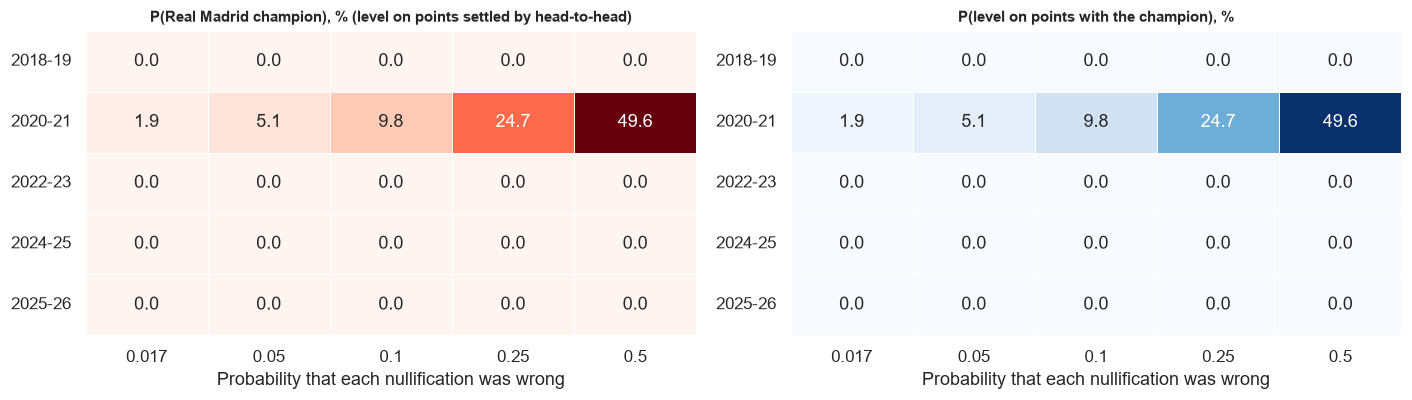

In [18]:
# Monte-Carlo: each nullified goal is independently WRONG with probability p (VAR error rate). How often would Real Madrid win/level the title?
rng = np.random.default_rng(2026)
N = 20000
p_list = [0.017, 0.05, 0.10, 0.25, 0.50]
mc = []
for s in no_title:
    ms = season_matches(s)
    t0 = tables[(s, "Actual")]
    teams = list(t0.team); base = t0.set_index("team").pts.reindex(teams).values.astype(float); ir = teams.index(RM)
    aff = []
    for (fid, team), k in A_adds.items():
        x = ms[ms.fs_id == fid]
        if len(x):
            x = x.iloc[0]
            gf, ga = (x.hg, x.ag) if x.home == team else (x.ag, x.hg)
            aff.append((teams.index(x.away if x.home == team else x.home), gf, ga, k))
    for p in p_list:
        delta = np.zeros((N, len(teams)))
        for io, gf, ga, k in aff:
            wr = rng.binomial(k, p, N)
            delta[:, ir] += pts_fn(gf + wr, ga) - pts_fn(gf, ga)
            delta[:, io] += pts_fn(ga, gf + wr) - pts_fn(ga, gf)
        newp = base + delta
        best_other = np.delete(newp, ir, axis=1).max(axis=1)
        mc.append(dict(season=s, p_wrong=p, p_title_strictly_ahead=np.mean(newp[:, ir] > best_other), p_level_on_points=np.mean(newp[:, ir] == best_other),
                       mean_points_gained=delta[:, ir].mean()))
mc = pd.DataFrame(mc)
tbf = be.set_index("season").rm_wins_head_to_head_tiebreak
mc["p_rm_champion"] = mc.p_title_strictly_ahead + mc.p_level_on_points * mc.season.map(tbf).astype(float)
piv = mc.pivot(index="season", columns="p_wrong", values="p_rm_champion")
piv2 = mc.pivot(index="season", columns="p_wrong", values="p_level_on_points")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.heatmap(piv * 100, annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=axes[0], linewidths=.5)
axes[0].set_title("P(Real Madrid champion), % (level on points settled by head-to-head)", fontsize=10); axes[0].set_xlabel("Probability that each nullification was wrong"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0)
sns.heatmap(piv2 * 100, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[1], linewidths=.5)
axes[1].set_title("P(level on points with the champion), %", fontsize=10); axes[1].set_xlabel("Probability that each nullification was wrong"); axes[1].set_ylabel("")
axes[1].tick_params(axis="y", rotation=0)
fig.tight_layout(); save(fig, "10_title_monte_carlo")

In [19]:
titles_actual = [s for s in seasons if s != "2026-27" and act.loc[s, "champion"] == RM]
def titles(prefix):
    x = sc_df[sc_df.scenario.str.startswith(prefix) & (sc_df.season != "2026-27")]
    return list(x[x.champion == RM].season)
titles_A, titles_B, titles_C = titles("A."), titles("B."), titles("C.")
champs_changed = sc_df[(sc_df.scenario.str.startswith("A.")) & sc_df.title_changed & (sc_df.season != "2026-27")]
champs_B = sc_df[(sc_df.scenario.str.startswith("B.")) & sc_df.title_changed & (sc_df.season != "2026-27")]
md(f"**Real Madrid titles - actual:** {', '.join(titles_actual)} ({len(titles_actual)}).  \n"
   f"**Scenario A (all 50 RM nullified goals counted, upper bound):** {', '.join(titles_A)} ({len(titles_A)}) - changes: **{', '.join(champs_changed.season) or 'none'}**.  \n"
   f"**Scenario B (every team's nullified goals counted):** {', '.join(titles_B)} ({len(titles_B)}) - champion changes in **{', '.join(champs_B.season) or 'none'}**.  \n"
   f"**Scenario C (A + goals ruled out on the pitch, extreme upper bound):** {', '.join(titles_C)} ({len(titles_C)}).")
display(sc_df[sc_df.scenario.str.startswith("A.") & (sc_df.season != "2026-27")][["season", "rm_pos", "rm_pts", "rm_pts_change", "champion", "champion_pts", "lead_over_best_rival", "title_changed"]]
        .merge(act[["rm_pos", "rm_pts", "champion", "champion_pts"]].add_suffix("_actual"), left_on="season", right_index=True))

**Real Madrid titles - actual:** 2019-20, 2021-22, 2023-24 (3).  
**Scenario A (all 50 RM nullified goals counted, upper bound):** 2019-20, 2020-21, 2021-22, 2023-24 (4) - changes: **2020-21**.  
**Scenario B (every team's nullified goals counted):** 2019-20, 2020-21, 2021-22, 2022-23 (4) - champion changes in **2020-21, 2022-23, 2023-24**.  
**Scenario C (A + goals ruled out on the pitch, extreme upper bound):** 2019-20, 2020-21, 2021-22, 2022-23, 2023-24, 2024-25 (6).

,season,rm_pos,rm_pts,rm_pts_change,champion,champion_pts,lead_over_best_rival,title_changed,rm_pos_actual,rm_pts_actual,champion_actual,champion_pts_actual
1,2018-19,3,69,1,FC Barcelona,87,-18,False,3,68,FC Barcelona,87
5,2019-20,1,91,4,Real Madrid,91,9,False,1,87,Real Madrid,87
9,2020-21,1,86,2,Real Madrid,86,0,True,2,84,Atlético de Madrid,86
13,2021-22,1,86,0,Real Madrid,86,13,False,1,86,Real Madrid,86
17,2022-23,2,85,7,FC Barcelona,86,-1,False,2,78,FC Barcelona,88
21,2023-24,1,97,2,Real Madrid,97,12,False,1,95,Real Madrid,95
25,2024-25,2,86,2,FC Barcelona,88,-2,False,2,84,FC Barcelona,88
29,2025-26,2,88,2,FC Barcelona,94,-6,False,2,86,FC Barcelona,94


## 6. Q5 - Further insights

### 6.1 Is the excess steady or driven by a few periods? Cumulative nullified goals

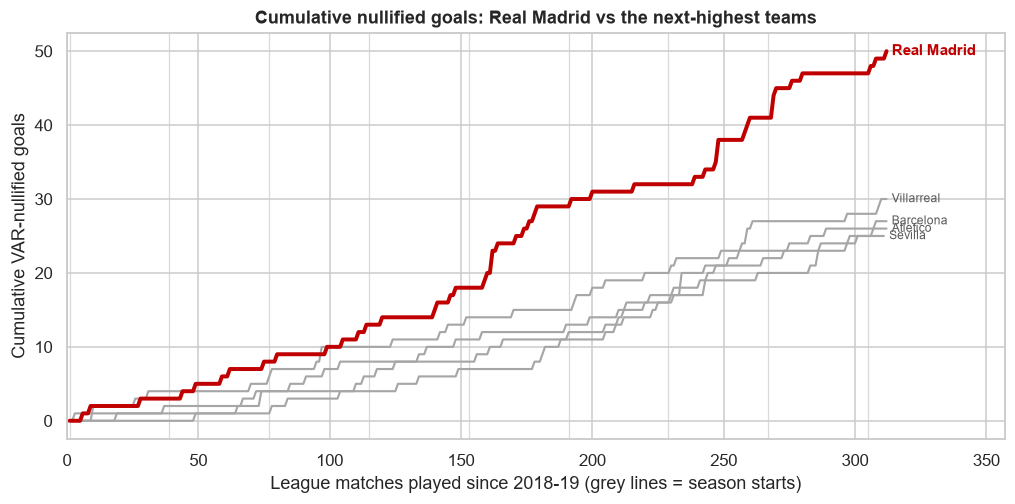

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.8))
peers = ["FC Barcelona", "Atlético de Madrid", "Villarreal", "Sevilla"]
for t in peers:
    x = tm[tm.team == t].sort_values("kickoff")
    ax.plot(np.arange(1, len(x) + 1), x.dis.cumsum().values, color=GREY, lw=1.4)
    ax.text(len(x) + 2, x.dis.cumsum().iloc[-1], t.replace("Atlético de Madrid", "Atletico").replace("FC ", ""), fontsize=8, va="center", color="#595959")
x = tm[tm.team == RM].sort_values("kickoff").reset_index(drop=True)
ax.plot(np.arange(1, len(x) + 1), x.dis.cumsum().values, color=RED, lw=2.6)
ax.text(len(x) + 2, x.dis.cumsum().iloc[-1], "Real Madrid", fontsize=10, va="center", color=RED, fontweight="bold")
seas_start = x.groupby("season").cumcount().eq(0)
for i in x.index[seas_start]:
    ax.axvline(i + 1, color="#D9D9D9", lw=.8, zorder=0)
ax.set_xlim(0, len(x) + 45); ax.set_xlabel("League matches played since 2018-19 (grey lines = season starts)"); ax.set_ylabel("Cumulative VAR-nullified goals")
ax.set_title("Cumulative nullified goals: Real Madrid vs the next-highest teams")
save(fig, "11_cumulative")

### 6.2 Funnel plot: is Real Madrid an outlier even allowing for chance? (rate per match vs 95% / 99.8% Poisson limits)

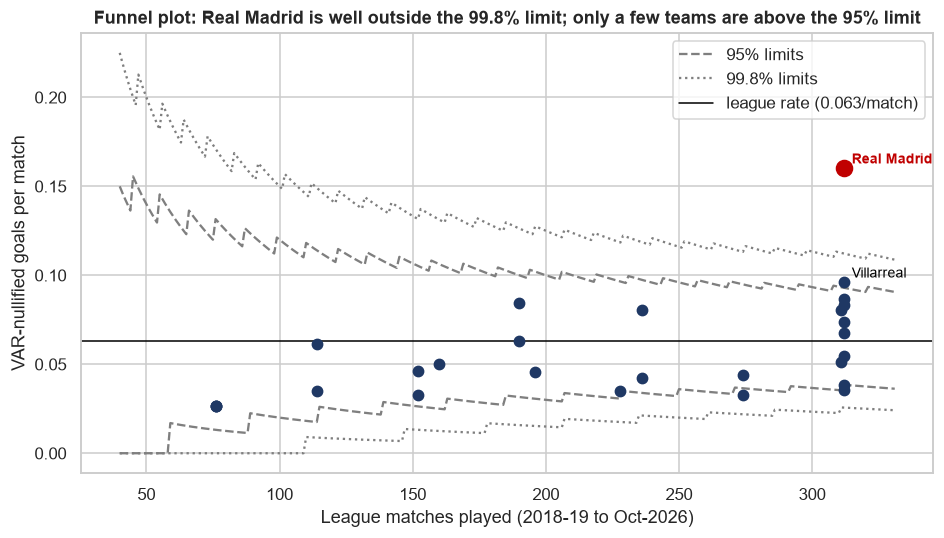

In [21]:
tt = tm.groupby("team").agg(matches=("fs_id", "size"), nullified=("dis", "sum")).reset_index()
tt = tt[tt.matches >= 40]
p0 = tt.nullified.sum() / tt.matches.sum()
n_ = np.arange(40, tt.matches.max() + 20)
fig, ax = plt.subplots(figsize=(10, 5.2))
for q, ls, lab in ((0.025, "--", "95% limits"), (0.001, ":", "99.8% limits")):
    ax.plot(n_, stats.poisson.ppf(1 - q, p0 * n_) / n_, color="#7F7F7F", ls=ls, label=lab)
    ax.plot(n_, stats.poisson.ppf(q, p0 * n_) / n_, color="#7F7F7F", ls=ls)
ax.axhline(p0, color="black", lw=1, label=f"league rate ({p0:.3f}/match)")
ax.scatter(tt.matches, tt.nullified / tt.matches, s=45, color=NAVY, zorder=3)
r_ = tt[tt.team == RM].iloc[0]
ax.scatter(r_.matches, r_.nullified / r_.matches, s=110, color=RED, zorder=4)
for r in tt.itertuples():
    if r.nullified / r.matches > stats.poisson.ppf(.975, p0 * r.matches) / r.matches or r.team == RM:
        ax.annotate(r.team.replace("Atlético de Madrid", "Atletico"), (r.matches, r.nullified / r.matches), xytext=(5, 3), textcoords="offset points", fontsize=9,
                    color=RED if r.team == RM else "black", fontweight="bold" if r.team == RM else None)
ax.set_xlabel("League matches played (2018-19 to Oct-2026)"); ax.set_ylabel("VAR-nullified goals per match")
ax.set_title("Funnel plot: Real Madrid is well outside the 99.8% limit; only a few teams are above the 95% limit"); ax.legend(loc="upper right")
save(fig, "12_funnel")

### 6.3 When and in what game situation? (timing, half, what the goal would have meant)

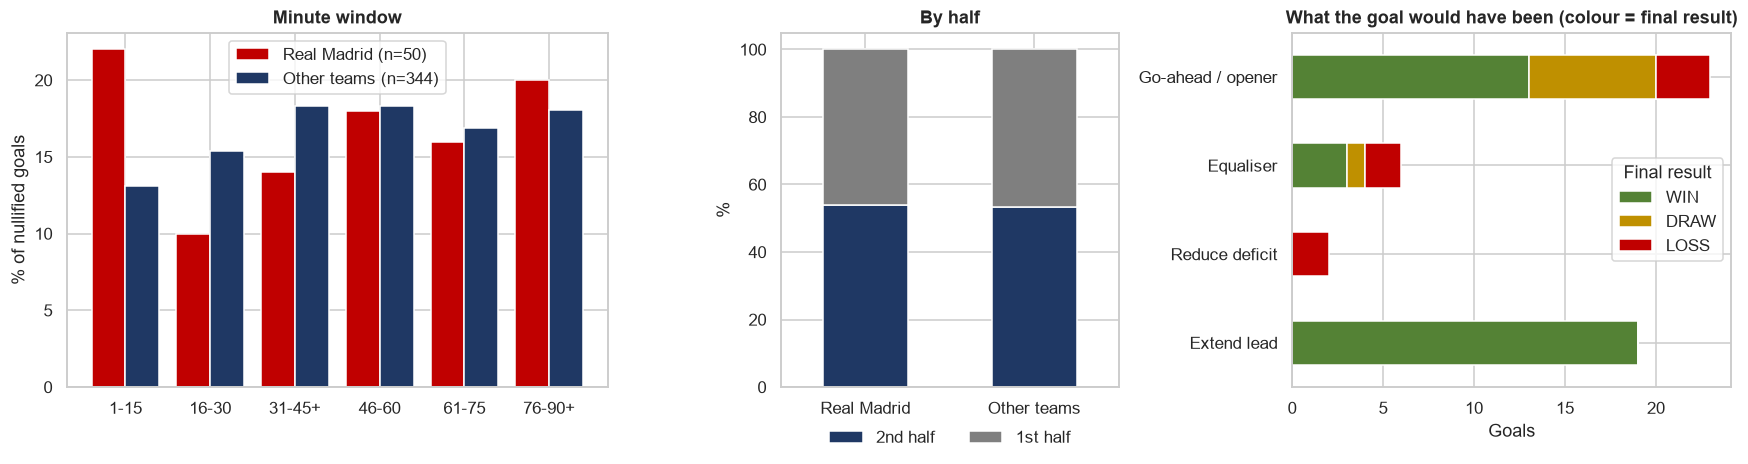

Stoppage-time share (45+/90+): Real Madrid 8% vs others 9%. Goals that would have been a go-ahead/opener or equaliser: 29 of 50.

In [22]:
def window(r):
    m = r.minute_num
    if r.half == 1:
        return "1-15" if m <= 15 else "16-30" if m <= 30 else "31-45+"
    return "46-60" if m <= 60 else "61-75" if m <= 75 else "76-90+"
order = ["1-15", "16-30", "31-45+", "46-60", "61-75", "76-90+"]
vd["window"] = vd.apply(window, axis=1)
rmw = vd[vd.team == RM].window.value_counts(normalize=True).reindex(order, fill_value=0) * 100
otw = vd[vd.team != RM].window.value_counts(normalize=True).reindex(order, fill_value=0) * 100
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.6, 1, 1.3]})
x = np.arange(len(order))
axes[0].bar(x - .2, rmw.values, .4, color=RED, label="Real Madrid (n=50)"); axes[0].bar(x + .2, otw.values, .4, color=NAVY, label=f"Other teams (n={int((vd.team != RM).sum())})")
axes[0].set_xticks(x); axes[0].set_xticklabels(order); axes[0].set_ylabel("% of nullified goals"); axes[0].legend(); axes[0].set_title("Minute window")
half = pd.DataFrame({"Real Madrid": rm.half_label.value_counts(normalize=True) * 100, "Other teams": vd[vd.team != RM].half_label.value_counts(normalize=True) * 100}).T
half.plot(kind="bar", stacked=True, ax=axes[1], color=[NAVY, "#7F7F7F"]); axes[1].set_title("By half"); axes[1].tick_params(axis="x", rotation=0); axes[1].set_ylabel("%")
axes[1].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
ge = pd.crosstab(rm.goal_effect, pd.Series(np.where(rm.team_gf > rm.team_ga, "WIN", np.where(rm.team_gf == rm.team_ga, "DRAW", "LOSS")), index=rm.index, name="Final result"))
ge = ge.reindex(columns=["WIN", "DRAW", "LOSS"], fill_value=0).loc[["Go-ahead / opener", "Equaliser", "Reduce deficit", "Extend lead"]]
ge.plot(kind="barh", stacked=True, ax=axes[2], color=["#548235", GOLD, RED]); axes[2].invert_yaxis()
axes[2].set_title("What the goal would have been (colour = final result)"); axes[2].set_xlabel("Goals"); axes[2].set_ylabel("")
axes[2].legend(title="Final result", loc="center right")
fig.tight_layout(); save(fig, "13_timing_and_game_state")
md(f"Stoppage-time share (45+/90+): Real Madrid {100 * rm.minute.str.contains(r'\+').mean():.0f}% vs others {100 * vd[vd.team != RM].minute.str.contains(r'\+').mean():.0f}%. "
   f"Goals that would have been a go-ahead/opener or equaliser: {int(rm.goal_effect.isin(['Go-ahead / opener', 'Equaliser']).sum())} of {len(rm)}.")

### 6.4 Venue, opponent strength and referee

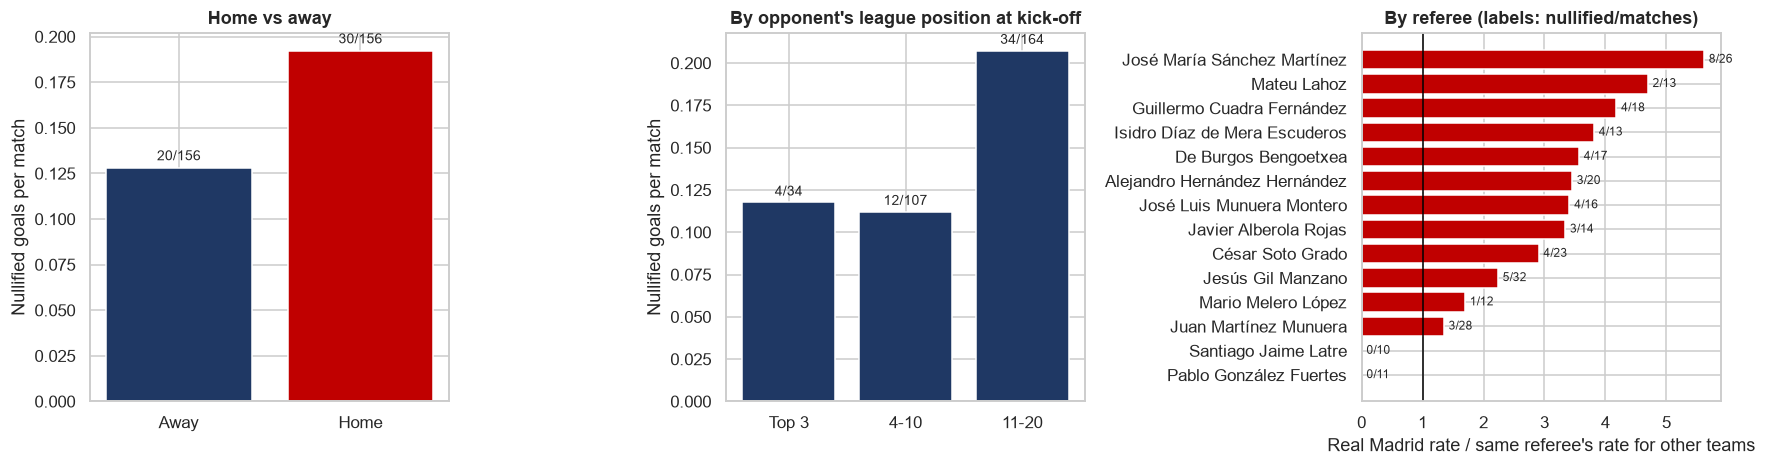

Real Madrid's nullified goals per match: **home 0.192** vs away 0.128; against teams outside the top 10 **0.207** vs 0.118 against top-3 teams. More of the nullified goals come at home against weaker, deeper-defending sides - consistent with the attacking-profile explanation (more attacks and runs in behind) rather than with a bias against Real Madrid in big games. The Real Madrid rate is above the same referee's rate for other teams for 12 of 14 referees with 10+ Real Madrid matches (small samples per referee).

In [23]:
opp_pos = tm[["fs_id", "team", "pos_before", "played_before"]].rename(columns={"team": "opponent", "pos_before": "opp_pos", "played_before": "opp_played"})
rmm = rm_matches.merge(opp_pos, on=["fs_id", "opponent"], how="left")
rmm["opp_group"] = pd.cut(rmm.opp_pos.where(rmm.opp_played > 0), [0, 3, 10, 20], labels=["Top 3", "4-10", "11-20"])
byv = rmm.groupby("venue").agg(matches=("fs_id", "size"), nullified=("dis", "sum")); byv["per_match"] = byv.nullified / byv.matches
byv.index = byv.index.map({"H": "Home", "A": "Away"})
byo = rmm.groupby("opp_group").agg(matches=("fs_id", "size"), nullified=("dis", "sum")); byo["per_match"] = byo.nullified / byo.matches

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, df_, ttl in ((axes[0], byv, "Home vs away"), (axes[1], byo, "By opponent's league position at kick-off")):
    ax.bar(df_.index.astype(str), df_.per_match, color=[RED if ttl.startswith("Home") and i == 1 else NAVY for i in range(len(df_))])
    for i, r in enumerate(df_.itertuples()):
        ax.text(i, r.per_match + .004, f"{r.nullified}/{r.matches}", ha="center", fontsize=9)
    ax.set_title(ttl); ax.set_ylabel("Nullified goals per match")
rf = O["ref"].query("rm_matches >= 10").sort_values("ratio_rm_vs_others_same_ref", ascending=True)
axes[2].barh(rf.referee, rf.ratio_rm_vs_others_same_ref, color=[RED if v > 1 else GREY for v in rf.ratio_rm_vs_others_same_ref])
axes[2].axvline(1, color="black", lw=1)
for i, r in enumerate(rf.itertuples()):
    axes[2].text(r.ratio_rm_vs_others_same_ref + .08, i, f"{r.rm_nullified}/{r.rm_matches}", va="center", fontsize=8)
axes[2].set_xlabel("Real Madrid rate / same referee's rate for other teams"); axes[2].set_title("By referee (labels: nullified/matches)")
fig.tight_layout(); save(fig, "14_venue_opponent_referee")
md(f"Real Madrid's nullified goals per match: **home {byv.loc['Home', 'per_match']:.3f}** vs away {byv.loc['Away', 'per_match']:.3f}; against teams outside the top 10 "
   f"**{byo.loc['11-20', 'per_match']:.3f}** vs {byo.loc['Top 3', 'per_match']:.3f} against top-3 teams. More of the nullified goals come at home against weaker, deeper-defending sides - "
   f"consistent with the attacking-profile explanation (more attacks and runs in behind) rather than with a bias against Real Madrid in big games. "
   f"The Real Madrid rate is above the same referee's rate for other teams for {int((rf.ratio_rm_vs_others_same_ref > 1).sum())} of {len(rf)} referees with 10+ Real Madrid matches (small samples per referee).")

### 6.5 How does Real Madrid's profile differ? (top-10 teams, Real Madrid / other top-10 teams, per match)
A ratio of 1 = same as the other top-10 teams. Offside flags, shots and passes in the opponent's pressing zone are where Real Madrid differs; fouls and cards are lower.

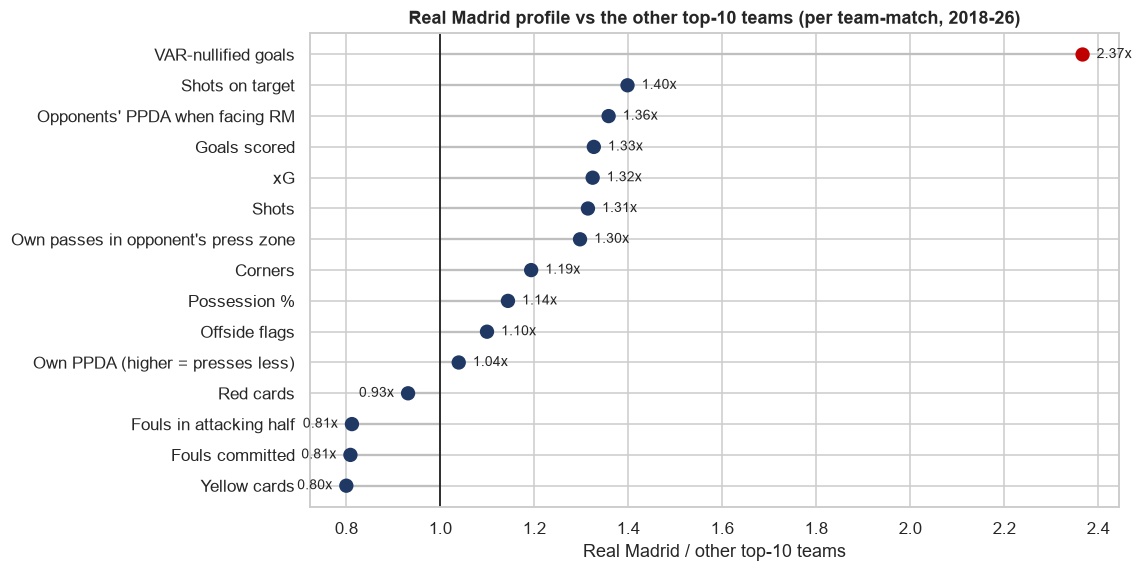

,rm,others,ratio
metric,,,
Yellow cards,1.88,2.35,0.80
Fouls committed,10.40,12.86,0.81
Fouls in attacking half,5.69,7.01,0.81
Red cards,0.10,0.11,0.93
Own PPDA (higher = presses less),11.27,10.84,1.04
Offside flags,2.36,2.14,1.10
Possession %,59.76,52.24,1.14
Corners,5.87,4.92,1.19
Own passes in opponent's press zone,331.65,255.65,1.30


In [24]:
t10 = tm[tm.top10 == True].copy()
metrics = {"VAR-nullified goals": "dis", "Goals scored": "gf", "Shots": "shots", "Shots on target": "sot", "xG": "xg", "Offside flags": "offsides", "Corners": "corners",
           "Possession %": "possession", "Fouls committed": "fouls", "Fouls in attacking half": "fouls_att_half", "Yellow cards": "yellow", "Red cards": "red",
           "Own PPDA (higher = presses less)": "ppda", "Opponents' PPDA when facing RM": "opp_ppda", "Own passes in opponent's press zone": "opp_ppda_att"}
rows = []
for lab, c in metrics.items():
    a, b = t10[t10.team == RM][c].mean(), t10[t10.team != RM][c].mean()
    rows.append(dict(metric=lab, rm=a, others=b, ratio=a / b))
prof = pd.DataFrame(rows).sort_values("ratio")
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.hlines(prof.metric, 1, prof.ratio, color="#BFBFBF")
ax.scatter(prof.ratio, prof.metric, color=[RED if m == "VAR-nullified goals" else NAVY for m in prof.metric], s=70, zorder=3)
ax.axvline(1, color="black", lw=1)
for r in prof.itertuples():
    ax.text(r.ratio + (.03 if r.ratio >= 1 else -.03), r.metric, f"{r.ratio:.2f}x", va="center", ha="left" if r.ratio >= 1 else "right", fontsize=9)
ax.set_xlabel("Real Madrid / other top-10 teams"); ax.set_title("Real Madrid profile vs the other top-10 teams (per team-match, 2018-26)")
save(fig, "15_profile_ratios")
prof.round(2).set_index("metric")

### 6.6 Does attacking volume or offside volume explain it? (top-10 team aggregates, 2018-2026)

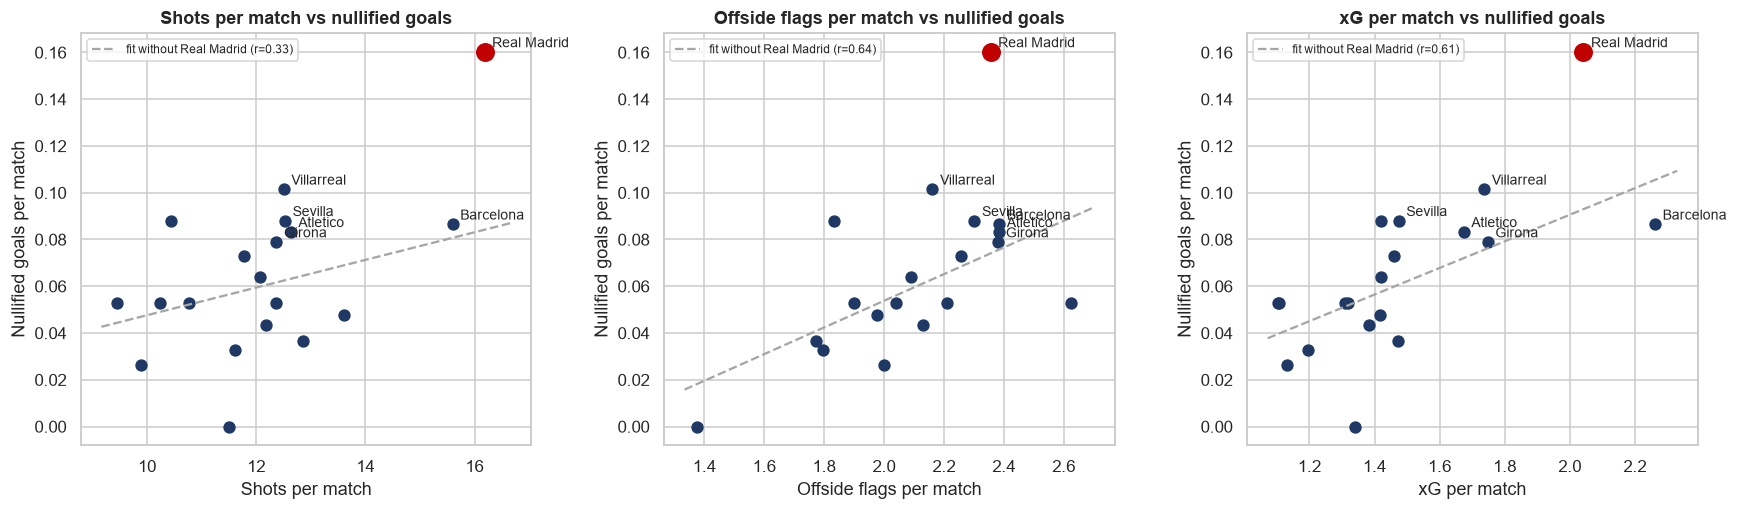

,n,pearson_r,pearson_p,spearman_rho
y,,,,
Shots (chances created),80,0.480,0.000,0.453
Shots on target,80,0.437,0.000,0.461
xG,80,0.491,0.000,0.514
Offsides (attacking positions),80,0.211,0.060,0.302
Corners,80,0.368,0.001,0.384
Goals scored,80,0.439,0.000,0.500


In [25]:
a = O["top10_agg"].copy()
cor = O["corr"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (col, lab) in zip(axes, (("shots_pm", "Shots per match"), ("offsides_pm", "Offside flags per match"), ("xg_pm", "xG per match"))):
    o_ = a[a.team != RM]
    sl, ic, r_, p_, _ = stats.linregress(o_[col], o_.dis_pm)
    xs = np.linspace(a[col].min() * .97, a[col].max() * 1.03, 50)
    ax.plot(xs, ic + sl * xs, color=GREY, ls="--", label=f"fit without Real Madrid (r={r_:.2f})")
    ax.scatter(o_[col], o_.dis_pm, color=NAVY, s=50)
    rr_ = a[a.team == RM].iloc[0]
    ax.scatter(rr_[col], rr_.dis_pm, color=RED, s=130, zorder=4)
    for r in a.itertuples():
        if r.team in (RM, "FC Barcelona", "Villarreal", "Atlético de Madrid", "Sevilla", "Girona"):
            ax.annotate(r.team.replace("Atlético de Madrid", "Atletico").replace("FC ", ""), (getattr(r, col), r.dis_pm), xytext=(5, 3), textcoords="offset points", fontsize=9)
    ax.set_xlabel(lab); ax.set_ylabel("Nullified goals per match"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title(f"{lab} vs nullified goals")
fig.tight_layout(); save(fig, "16_attack_volume_scatter")
display(cor[cor.scope.str.contains("8 full seasons \\(counts\\)")][["y", "n", "pearson_r", "pearson_p", "spearman_rho"]].round(3).set_index("y"))

### 6.7 How much of the excess is explained after controlling for attack volume, pressing and discipline? (Poisson models; Real Madrid incident-rate ratio)

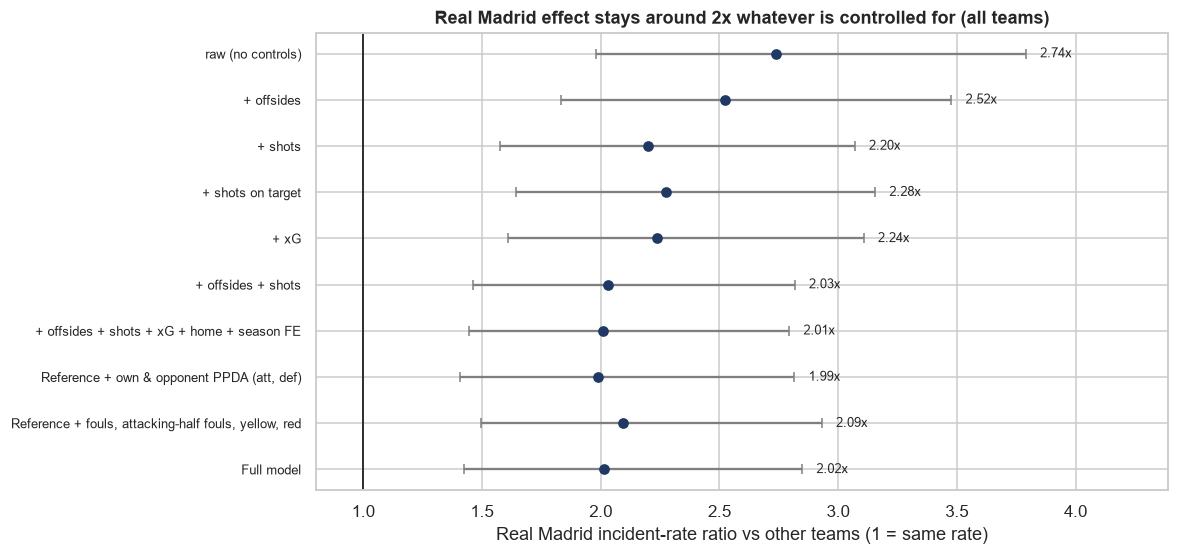

In [26]:
rows = []
def add(df_, scope, label, group):
    x = df_[df_.scope == scope]
    for r in x.itertuples():
        rows.append(dict(group=group, model=r.model if label is None else label(r.model), irr=r.rm_irr, lo=r.irr_ci_low, hi=r.irr_ci_high))
allscope = "All 20 teams per season"
g1 = O["glm"][O["glm"].scope == allscope]
for r in g1.itertuples():
    rows.append(dict(group="Attack volume", model=r.model.split(":")[0] + ": " + (r.model.split(":", 1)[1].strip() if ":" in r.model else ""), irr=r.rm_irr, lo=r.irr_ci_low, hi=r.irr_ci_high))
pgl = O["ppda_glm"][O["ppda_glm"].scope == allscope]
rows.append(dict(group="+ pressing (PPDA)", model="Reference + own & opponent PPDA (att, def)", irr=pgl.iloc[-1].rm_irr, lo=pgl.iloc[-1].irr_ci_low, hi=pgl.iloc[-1].irr_ci_high))
dgl = O["disc_glm"][O["disc_glm"].scope == allscope]
rows.append(dict(group="+ discipline", model="Reference + fouls, attacking-half fouls, yellow, red", irr=dgl.iloc[6].rm_irr, lo=dgl.iloc[6].irr_ci_low, hi=dgl.iloc[6].irr_ci_high))
rows.append(dict(group="+ discipline & pressing", model="Full model", irr=dgl.iloc[-1].rm_irr, lo=dgl.iloc[-1].irr_ci_low, hi=dgl.iloc[-1].irr_ci_high))
fo = pd.DataFrame(rows)
fo["model"] = fo.model.str.replace("M0 raw: RM indicator only", "M0 raw (no controls)").str.replace(r"^M\d ", "", regex=True).str.rstrip(": ")
fig, ax = plt.subplots(figsize=(10, 5.4))
y = np.arange(len(fo))[::-1]
ax.errorbar(fo.irr, y, xerr=[fo.irr - fo.lo, fo.hi - fo.irr], fmt="o", color=NAVY, ecolor="#7F7F7F", capsize=3)
ax.axvline(1, color="black", lw=1)
ax.set_yticks(y); ax.set_yticklabels(fo.model, fontsize=8.5)
for yy, r in zip(y, fo.itertuples()):
    ax.text(r.hi + .06, yy, f"{r.irr:.2f}x", va="center", fontsize=8.5)
ax.set_xlabel("Real Madrid incident-rate ratio vs other teams (1 = same rate)"); ax.set_xlim(0.8, max(fo.hi) + .6)
ax.set_title("Real Madrid effect stays around 2x whatever is controlled for (all teams)")
save(fig, "17_irr_forest")

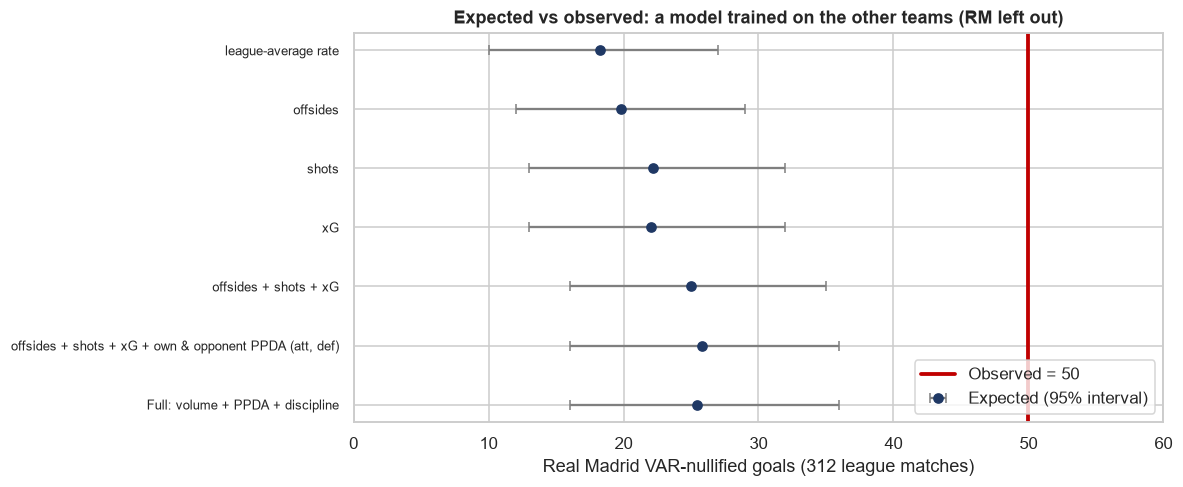

In [27]:
fc = pd.concat([O["forecast"].assign(kind="Volume models"), O["ppda_fc"].assign(kind="+ PPDA"), O["disc_fc"].assign(kind="+ discipline")], ignore_index=True)
fc = fc[fc.scope == allscope].reset_index(drop=True)
fc["label"] = fc.model_trained_on_other_teams.str.replace("matches only (league average rate)", "league-average rate").str.replace("Full discipline + PPDA model", "Full: volume + PPDA + discipline")
fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(fc))[::-1]
ax.errorbar(fc.rm_expected, y, xerr=[fc.rm_expected - fc.expected_p2_5, fc.expected_p97_5 - fc.rm_expected], fmt="o", color=NAVY, ecolor="#7F7F7F", capsize=3, label="Expected (95% interval)")
ax.axvline(fc.rm_observed.iloc[0], color=RED, lw=2.5, label=f"Observed = {int(fc.rm_observed.iloc[0])}")
ax.set_yticks(y); ax.set_yticklabels(fc.label, fontsize=8.5); ax.set_xlabel("Real Madrid VAR-nullified goals (312 league matches)")
ax.set_title("Expected vs observed: a model trained on the other teams (RM left out)"); ax.legend(loc="lower right"); ax.set_xlim(0, 60)
save(fig, "18_expected_vs_observed")

### 6.8 VAR vs on-field decisions, and the reason mix

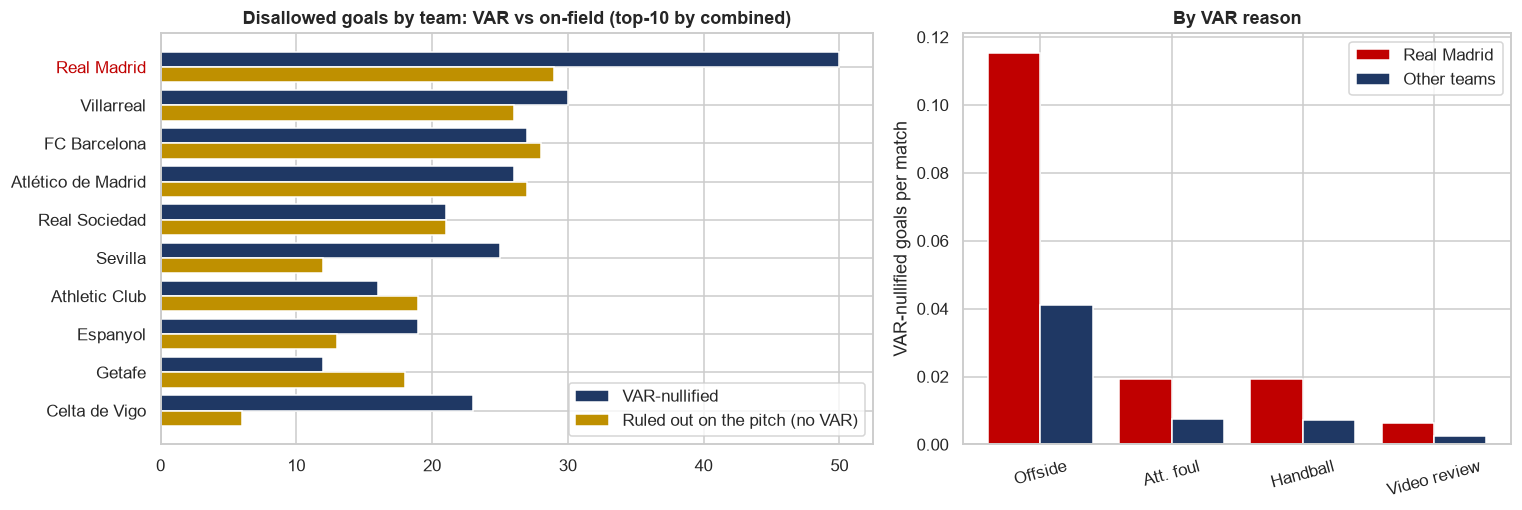

,model,term,irr,ci_low,ci_high,p_value
0,Raw,Real Madrid effect on on-field disallowed goals (IRR),2.021,1.383,2.953,0.000
1,Raw,Extra Real Madrid effect at the VAR stage vs on-field (I...,1.356,0.824,2.232,0.231
2,"Controlled (offsides, shots, xG, home, season FE)",Real Madrid effect on on-field disallowed goals (IRR),1.456,1.002,2.116,0.049
3,"Controlled (offsides, shots, xG, home, season FE)",Extra Real Madrid effect at the VAR stage vs on-field (I...,1.356,0.824,2.232,0.231


In [28]:
ot = O["onf_teams"].head(10).copy()
rr_ = O["reason_rates"].query("scope == @allscope and reason != 'All reasons'")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
y = np.arange(len(ot))
axes[0].barh(y - .2, ot.var_nullified, .4, color=NAVY, label="VAR-nullified"); axes[0].barh(y + .2, ot.onfield, .4, color=GOLD, label="Ruled out on the pitch (no VAR)")
axes[0].set_yticks(y); axes[0].set_yticklabels(ot.team); axes[0].invert_yaxis(); axes[0].legend(loc="lower right")
axes[0].get_yticklabels()[0].set_color(RED)
axes[0].set_title("Disallowed goals by team: VAR vs on-field (top-10 by combined)")
x = np.arange(len(rr_) // 1)
axes[1].bar(x - .2, rr_.rm_per_match, .4, color=RED, label="Real Madrid"); axes[1].bar(x + .2, rr_.others_per_match, .4, color=NAVY, label="Other teams")
axes[1].set_xticks(x); axes[1].set_xticklabels([r.replace(" (unspecified)", "").replace("Attacking foul", "Att. foul") for r in rr_.reason], rotation=15)
axes[1].set_ylabel("VAR-nullified goals per match"); axes[1].legend(); axes[1].set_title("By VAR reason")
fig.tight_layout(); save(fig, "19_var_vs_onfield_and_reasons")
O["onf_inter"].query("scope == @allscope")[["model", "term", "irr", "ci_low", "ci_high", "p_value"]].round(3)

### 6.9 Net points ledger: points lost to a team's own nullified goals vs points kept because an opponent's goal was nullified

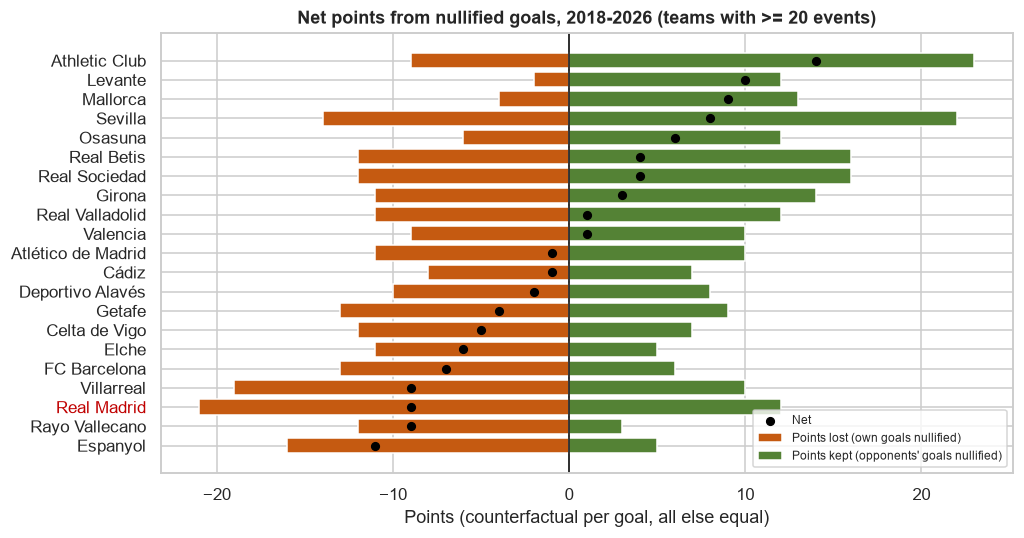

In [29]:
L = O["ledger"].copy()
L = L[(L.own_nullified + L.opp_nullified_against_them) >= 20].sort_values("net_points_from_nullified_goals")
fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(L))
ax.barh(y, -L.points_lost, color="#C55A11", label="Points lost (own goals nullified)")
ax.barh(y, L.points_kept, color="#548235", label="Points kept (opponents' goals nullified)")
ax.scatter(L.net_points_from_nullified_goals, y, color="black", zorder=3, s=25, label="Net")
ax.set_yticks(y); ax.set_yticklabels(L.team); ax.axvline(0, color="black", lw=1); ax.legend(loc="lower right", fontsize=8)
for t in ax.get_yticklabels():
    if t.get_text() == RM:
        t.set_color(RED)
ax.set_xlabel("Points (counterfactual per goal, all else equal)"); ax.set_title("Net points from nullified goals, 2018-2026 (teams with >= 20 events)")
save(fig, "20_net_points_ledger")

## 7. Conclusions

In [30]:
tight = be.sort_values("gap_pts").iloc[0]
irr_full = O["disc_glm"].query("scope == @allscope").iloc[-1]
fun_n = int(len(rm_matches)); up99 = stats.poisson.ppf(0.999, p0 * fun_n) / fun_n
realistic = mc[mc.p_wrong <= 0.05].p_rm_champion.max()
second = vd.team.value_counts()
top2 = pc.iloc[:2]
led_rm = O["ledger"].query("team == @RM").iloc[0]
sc_B = lambda s: sc_df[(sc_df.season == s) & sc_df.scenario.str.startswith("B.")].iloc[0]
lead_A = {s: int(sc_df[(sc_df.season == s) & sc_df.scenario.str.startswith("A.")].lead_over_best_rival.iloc[0]) for s in seasons}
nxt = pc.iloc[2:4]
big_seasons = ss[ss.status == "Not champion"].sort_values("nullified", ascending=False).head(2)
other_gaps = ", ".join(f"{s} ({-lead_A[s]} pt{'s' if lead_A[s] != -1 else ''} behind)" for s in no_title if lead_A[s] < 0)
med_top3 = conc[conc.team != RM].top3_share.median()
md(f'''
1. **The outlier is real.** Real Madrid has **{len(rm)}** VAR-nullified goals vs **{second.iloc[1]}** for the next team ({second.index[1]}), i.e. {len(rm) / fun_n:.3f} per match vs a league rate of {p0:.3f}; the funnel plot puts it {'above' if len(rm) / fun_n > up99 else 'inside'} the 99.8% limit ({up99:.3f} per match).
2. **Q1 - player concentration.** **{k75} of {len(pc)} players account for {share75:.0%} of the incidents** (75% threshold): {top2.index[0]} and {top2.index[1]} lead with {top2.iloc[0]} each ({top2.sum() / len(rm):.0%} together), then {nxt.index[0]} and {nxt.index[1]} with {nxt.iloc[0]} each. Concentration is typical for a team of this size: Real Madrid's top-3 share is {conc.set_index('team').loc[RM].top3_share:.0%} vs a median of {med_top3:.0%} for the other teams with 15+ nullified goals, so the incidents follow whoever plays in the front line rather than one player.
3. **Q2 - matches affected.** {len(rm)} goals fall in **{n_matches}** matches ({100 * n_matches / len(rm_matches):.1f}% of Real Madrid league matches). **{len(dl)}** of them ended in a draw or loss ({100 * len(dl) / n_matches:.0f}% of the affected matches), and in **{len(chg)}** the result would have changed if every nullified goal had counted: **{int(g.points_lost.sum())} points** in 8.2 seasons (about {g.points_lost.sum() / 8.2:.1f} per season).
4. **Q3 - champion vs not.** {int(ch.nullified)} nullified goals in {int(ch.seasons)} title seasons ({ch['per 38 matches']:.1f} per 38 matches, {ch['% of all RM nullified goals']:.0f}% of the total) vs {int(nc.nullified)} in {int(nc.seasons)} non-title seasons ({nc['per 38 matches']:.1f} per 38, {nc['% of all RM nullified goals']:.0f}%). The rate is lower in title seasons but the difference is not statistically significant (rate ratio {rr:.2f}, p = {bt.pvalue:.2f}); {big_seasons.season.iloc[0]} and {big_seasons.season.iloc[1]} ({big_seasons.nullified.iloc[0]} and {big_seasons.nullified.iloc[1]} goals) drive the non-title figure.
5. **Q4 - title scenarios.** Counting **every** Real Madrid nullified goal as wrong (scenario A, an upper bound) changes **one** title: **{', '.join(champs_changed.season) or 'none'}** - Real Madrid would have been level on {int(tight.gap_pts) + int(act.loc[tight.season, 'rm_pts'])} points with {tight.champion} and ahead on head-to-head (h2h points {tight.h2h_points_rm_vs_champion}); that needs only **{tight.min_wrong_calls_to_level}** wrong call (a draw turned into a win), vs about {tight.expected_wrong_calls_at_98pct_accuracy} expected at 98% VAR accuracy. In the other non-title seasons Real Madrid would still have finished behind even with every nullified goal counted: {other_gaps}. With a realistic 2-5% error rate the chance of overturning any title is at most **{realistic:.1%}**.
6. **Is the VAR the cause?** In a symmetric world where *every* team's nullified goals count (scenario B) Real Madrid gains 2022-23 but loses 2023-24 ({sc_B('2023-24').rm_pts} vs {sc_B('2023-24').champion_pts} pts): the nullifications cancel out over the league (Real Madrid net {led_rm.net_points_from_nullified_goals:.0f} points, similar to Villarreal and Barcelona). Real Madrid's excess is also present in goals ruled out *on the pitch* without VAR, the extra effect at the VAR stage is not significant, and the Real Madrid rate stays about **{irr_full.rm_irr:.1f}x** after controlling for attack volume, offsides, pressing and discipline.
7. **What remains unexplained** (about 2x after controls) is most consistent with Real Madrid's attacking profile (1.3x shots, 1.3x passes in the opponent's press zone, opponents pressing it far less) - a hypothesis that would need offside-line tracking data to confirm.
''')


1. **The outlier is real.** Real Madrid has **50** VAR-nullified goals vs **30** for the next team (Villarreal), i.e. 0.160 per match vs a league rate of 0.063; the funnel plot puts it above the 99.8% limit (0.112 per match).
2. **Q1 - player concentration.** **11 of 23 players account for 76% of the incidents** (75% threshold): Karim Benzema and Kylian Mbappé lead with 8 each (32% together), then Marco Asensio and Vinícius Júnior with 4 each. Concentration is typical for a team of this size: Real Madrid's top-3 share is 40% vs a median of 38% for the other teams with 15+ nullified goals, so the incidents follow whoever plays in the front line rather than one player.
3. **Q2 - matches affected.** 50 goals fall in **44** matches (14.1% of Real Madrid league matches). **15** of them ended in a draw or loss (34% of the affected matches), and in **13** the result would have changed if every nullified goal had counted: **21 points** in 8.2 seasons (about 2.6 per season).
4. **Q3 - champion vs not.** 13 nullified goals in 3 title seasons (4.3 per 38 matches, 26% of the total) vs 34 in 5 non-title seasons (6.8 per 38, 68%). The rate is lower in title seasons but the difference is not statistically significant (rate ratio 0.64, p = 0.18); 2022-23 and 2024-25 (11 and 9 goals) drive the non-title figure.
5. **Q4 - title scenarios.** Counting **every** Real Madrid nullified goal as wrong (scenario A, an upper bound) changes **one** title: **2020-21** - Real Madrid would have been level on 86 points with Atlético de Madrid and ahead on head-to-head (h2h points 4-1); that needs only **1** wrong call (a draw turned into a win), vs about 0.09 expected at 98% VAR accuracy. In the other non-title seasons Real Madrid would still have finished behind even with every nullified goal counted: 2018-19 (18 pts behind), 2022-23 (1 pt behind), 2024-25 (2 pts behind), 2025-26 (6 pts behind). With a realistic 2-5% error rate the chance of overturning any title is at most **5.1%**.
6. **Is the VAR the cause?** In a symmetric world where *every* team's nullified goals count (scenario B) Real Madrid gains 2022-23 but loses 2023-24 (87 vs 88 pts): the nullifications cancel out over the league (Real Madrid net -9 points, similar to Villarreal and Barcelona). Real Madrid's excess is also present in goals ruled out *on the pitch* without VAR, the extra effect at the VAR stage is not significant, and the Real Madrid rate stays about **2.0x** after controlling for attack volume, offsides, pressing and discipline.
7. **What remains unexplained** (about 2x after controls) is most consistent with Real Madrid's attacking profile (1.3x shots, 1.3x passes in the opponent's press zone, opponents pressing it far less) - a hypothesis that would need offside-line tracking data to confirm.


In [31]:
# export the new tables for reuse
g.to_csv(P / "eda_rm_matches_with_nullified.csv", index=False, encoding="utf-8-sig")
ss.to_csv(P / "eda_champion_vs_not.csv", index=False, encoding="utf-8-sig")
sc_df.to_csv(P / "eda_title_scenarios.csv", index=False, encoding="utf-8-sig")
be.to_csv(P / "eda_title_break_even.csv", index=False, encoding="utf-8-sig")
mc.to_csv(P / "eda_title_monte_carlo.csv", index=False, encoding="utf-8-sig")
lb = pd.concat([t.head(6).assign(season=s, scenario=sc) for (s, sc), t in tables.items()], ignore_index=True)
lb.to_csv(P / "eda_title_leaderboards.csv", index=False, encoding="utf-8-sig")
pc.rename("nullified_goals").to_frame().to_csv(P / "eda_player_concentration.csv", encoding="utf-8-sig")
print("figures:", sorted(p.name for p in FIG.glob("*.png")))

figures: ['01_team_ranking.png', '02_team_season_heatmap.png', '03_player_pareto.png', '04_concentration_vs_teams.png', '05_player_offside_flags.png', '06_games_affected.png', '07_champion_vs_not.png', '08_title_scenarios_gap.png', '09_title_scenarios_top4.png', '10_title_monte_carlo.png', '11_cumulative.png', '12_funnel.png', '13_timing_and_game_state.png', '14_venue_opponent_referee.png', '15_profile_ratios.png', '16_attack_volume_scatter.png', '17_irr_forest.png', '18_expected_vs_observed.png', '19_var_vs_onfield_and_reasons.png', '20_net_points_ledger.png']
